## Image Processing and Computer Vision - Assignment Module #2


Alessandro Teodori (0001247539) alessandro.teodori3@studio.unibo.it

Juan Guillermo Jaramillo Saa (0001217725) juan.jaramillosaa@studio.unibo.it

Ubalducci Michele (0001226810) michele.ubalducci@studio.unibo.it

This notebook contains the whole assignment, one part after the other, and shares the code between the parts: the
data pipeline, the training loop, the experiment runner, the storage of the results and the plots are defined once and
used by every experiment.

| part | content | results |
|---|---|---|
| **Part 1** | a convolutional network designed and trained from scratch, with ablation study and tuning | `results/part1` |
| **Part 2A** | fine-tuning of the pretrained ResNet-18 with the training hyperparameters of the best model of Part 1 | `results/part2A` |
| **Part 2B** | fine-tuning with tuned hyperparameters | *to be added* |

# Part 1: design your own network

We train a convolutional network from scratch on the 100 aircraft variants of FGVC-Aircraft, using only PyTorch
primitives (`nn.Conv2d`, `nn.BatchNorm2d`, `nn.Linear`, ...). Our goal is not only a good accuracy but a network in
which every component is justified by a measurement. We therefore build it as a **ladder**: we start from a plain
VGG-style network and change **one design choice at a time**, so that every difference in accuracy has a single
cause.

| part | what we train | question |
|---|---|---|
| **ladder** s0 | plain VGG: 3 stages x 1 block, no BatchNorm, flatten head, no augmentation | reference point |
| s1 | + BatchNorm after every convolution | does BN improve the network and its tolerance to the learning rate? |
| s2 | + global average pooling instead of flatten | is the large flatten head responsible for memorization? |
| s3 | + random resized crop and horizontal flip | how much does augmentation limit memorization? |
| s4 | + a 4th stage (512 channels) | does more capacity help once the network is regularized? |
| **depth x residual** | {plain, residual} x {11, 19, 31 convolutional layers}, three seeds each | do skip connections matter, and more so as depth grows? |
| **training recipe** | the three best networks + weight decay, label smoothing, dropout, random erasing, crop size and schedule, tuned by grid search, random search and confirmation with three seeds | which network is best once each one has its own tuned recipe? |
| **longer training** | the three tuned networks, same configuration, 150 epochs instead of 70 (three seeds) | does more training help, and which network is final? |
| **ablation** | the final network with one component removed at a time and retrained (three seeds) | does every component of the final model contribute to its accuracy? |

**Protocol.** All runs share the same budget: 224x224 images, 70 epochs, batch 64, SGD with momentum, 3 warmup
epochs followed by cosine decay. Each configuration is trained at three learning rates (0.1, 0.05, 0.01) and
represented by the best one, since different networks prefer different learning rates. Weight decay, label
smoothing, dropout and random erasing are disabled until the training recipe, so that the ladder and the depth x residual
experiment measure the architecture alone. **All choices are made on the validation split; test accuracy is only
reported.**

**Result.** The final model is a residual network with 31 convolutional layers (the stage layout of ResNet-34 with a
single block in the last stage), trained for 150 epochs with the tuned recipe: **74.0% ± 0.7 validation and
74.2% ± 0.2 test accuracy** (mean ± std over three seeds).

## Setup (shared by all parts)

**How to run.** The notebook runs top to bottom, locally or on Colab, and needs no access to Google Drive. All the
runs reported below are stored in a shared Google Drive folder (a copy of the `results` directory) and the ones
missing from the local `results` directory are downloaded automatically with `gdown`. With `TRAIN = False` (the
default) the notebook only loads the stored results and shows its tables and plots: no dataset and no training are
needed. With `TRAIN = True` the training cells (final model, ablation, Part 2A) download the dataset and train the
runs whose result does not exist yet; `RETRAIN = True` trains them again even if it exists. The images are read and
preprocessed on the fly, on the CPU. Locally, results are kept in the `results` directory of the repository and the
dataset in its `data` directory (git-ignored, created if missing); on Colab both stay on the temporary disk of the
session.

**Note.** The stored results were produced with an equivalent pipeline that kept the dataset on the GPU and
computed the augmentation on the GPU with mixed precision. The training code of this notebook is the same algorithm
with standard torchvision transforms in float32, so retraining gives similar, not identical, numbers.

In [1]:
%pip install -q gdown

/Users/alessandroteodori/code/100planes-X-IPCV/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import math
import random
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T
from torchvision.transforms import functional as TF
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

IN_COLAB = "google.colab" in sys.modules
DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)

TRAIN = False  # True: run the training cells (final model, ablation, Part 2A) and download the dataset
RETRAIN = False  # True: with TRAIN, retrain the runs whose JSON already exists too
print(
    f"device: {DEVICE}"
    + (f" ({torch.cuda.get_device_name()})" if DEVICE.type == "cuda" else "")
    + f" | torch {torch.__version__}"
)

device: mps | torch 2.14.1


/Users/alessandroteodori/code/100planes-X-IPCV/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Paths

Results and the dataset are kept in the repository (`results/`, `data/`) when the
notebook runs locally, and on the temporary disk of the session on Colab. The stored results of the project are then
downloaded with `gdown` from the shared Google Drive folder, which holds a copy of the `results` directory: only the
files that are not already there, and existing files are never overwritten.

In [3]:
if IN_COLAB:
    RESULTS_ROOT = Path("/content/results")
    DATA_ROOT = Path("/content/data")
else:
    REPO_DIR = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
    RESULTS_ROOT = REPO_DIR / "results"
    DATA_ROOT = (
        REPO_DIR / "data"
    )  # dataset: git-ignored, created if missing
RESULTS_DIR = RESULTS_ROOT / "part1"
RESULTS_DIR_2A = RESULTS_ROOT / "part2A"

for d in (RESULTS_DIR, RESULTS_DIR_2A, DATA_ROOT):
    d.mkdir(parents=True, exist_ok=True)
print("results ->", RESULTS_ROOT)

GDRIVE_FOLDER = "https://drive.google.com/drive/folders/1KfN4HcjaVCuXfqei8PaubVUVhffhJan2"  # copy of results/
FETCH_RESULTS = True  # False: use only the results already in RESULTS_ROOT


def fetch_results(folder_url, dest_root):
    # List the shared Google Drive folder (a copy of results/) and download with gdown the JSON files that are not in
    # dest_root yet, never overwriting an existing file.
    import gdown

    files = gdown.download_folder(
        url=folder_url, skip_download=True, quiet=True, use_cookies=False
    )
    added = kept = failed = 0
    last_error = None
    for f in tqdm(files, desc="results from Google Drive"):
        path = Path(f.path)
        if (
            path.suffix != ".json"
            or path.is_absolute()
            or ".." in path.parts
            or any(p.startswith(".") for p in path.parts)
        ):
            continue
        target = dest_root / path
        if target.exists():
            kept += 1
            continue
        target.parent.mkdir(parents=True, exist_ok=True)
        try:
            ok = (
                gdown.download(
                    id=f.id, output=str(target), quiet=True, use_cookies=False
                )
                is not None
            )
        except Exception as e:  # e.g. the daily download quota of the file is exceeded
            ok = False
            last_error = e
        failed += not ok
        added += ok
    print(
        f"results from Google Drive: {added} downloaded, {kept} already present"
        + (
            f", {failed} FAILED (rerun the cell to retry): {last_error}"
            if failed
            else ""
        )
    )


if FETCH_RESULTS:
    try:
        fetch_results(GDRIVE_FOLDER, RESULTS_ROOT)
    except Exception as e:
        print(
            f"WARNING: could not download the results from Google Drive ({e}); using the ones already in {RESULTS_ROOT}"
        )

results -> /Users/alessandroteodori/code/100planes-X-IPCV/results


results from Google Drive: 100%|██████████| 237/237 [00:00<00:00, 47751.84it/s]

results from Google Drive: 0 downloaded, 237 already present


### Reproducibility

We seed every source of randomness (initialization, data order, augmentation) and keep cuDNN deterministic, so that a
configuration trained twice with the same seed gives the same result. Training a configuration with different seeds
is how we measure run-to-run noise.

In [4]:
def fix_random(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


fix_random(42)

## Configuration

`BASE` holds every fixed choice; each run is `BASE` plus a few overrides.

| choice | value | motivation |
|---|---|---|
| resolution | 224 x 224 | see below |
| stem | 3x3 s2 (32) -> 3x3 (32) -> 3x3 (64) -> maxpool s2 | see *The network* |
| block | two 3x3 convolutions (ResNet "basic block") | the same block becomes residual by adding its input back |
| width | 64 -> 128 -> 256 (-> 512) | doubles at every stage while the resolution halves, as in VGG and ResNet |
| BatchNorm | after every convolution, before the ReLU, also on the 1x1 projection of a skip; no bias in convolutions followed by BN | standard ResNet placement; BN cancels the bias |
| initialization | Kaiming normal (fan_out, ReLU) | keeps activations at a stable scale through depth, which matters most without BN |
| optimizer | SGD, momentum 0.9 | optimizer of VGG and ResNet, standard for training CNNs from scratch with a learning-rate schedule (lecture 6) |
| learning rate | best of 0.1 / 0.05 / 0.01 on validation; in the training recipe searched jointly with the weight decay | see below |
| schedule | 3 warmup epochs, then cosine decay to 0 | with a constant learning rate the accuracy keeps oscillating, so the result depends on when training stops; the decay lets the network settle (Loshchilov & Hutter, ICLR 2017). The warmup avoids large updates while the weights are still random |
| epochs | 70 (150 for the final, longer training) | a compromise between convergence and the number of runs the study requires; the selected networks are then trained longer |
| regularizers | off in the ladder and in the depth x residual experiment, searched in the training recipe | they belong to the training recipe, not to the architecture |

**Resolution.** 224x224 is the standard resolution of ImageNet training (AlexNet, VGG, ResNet) and the resolution of
the pretrained ResNet-18 of Part 2, which keeps the two parts comparable. Fine-grained classification often benefits
from higher resolutions (e.g. 448px in Lin et al., *Bilinear CNN*, 2015), at a cost that grows with the number of
pixels; we keep 224px for the study.

**Learning-rate sweep.** The best learning rate depends on the network: without BatchNorm, or with a large flatten
head, a network becomes unstable at learning rates that a network with BN and global average pooling handles well.
With a single learning rate, a step could look harmful only because that value does not suit it, so we compare every
configuration at its own best learning rate. The three log-spaced values (lecture 6) cover both regimes.

In [5]:
BASE = dict(
    seed=42,
    # data
    img_size=224,
    augment=False,
    crop_scale=(
        0.5,
        1.0,
    ),  # RandomResizedCrop: area of the crop, as a fraction of the image
    # architecture
    stem=(32, 32, 64),
    channels=(64, 128, 256),
    blocks=(1, 1, 1),  # blocks per stage; a block is two 3x3 convs
    batchnorm=False,
    gap=False,
    residual=False,
    dropout=0.0,  # before the classifier; searched in the training recipe
    # training
    epochs=70,
    batch_size=64,
    lr=0.05,  # overridden by the sweep
    momentum=0.9,
    weight_decay=0.0,  # searched in the training recipe
    label_smoothing=0.0,  # searched in the training recipe
    random_erasing=0.0,  # probability of erasing a random rectangle; searched in the training recipe
    warmup_epochs=3,
)

# every configuration is trained at each of these learning rates and represented by its best one (on validation)
LR_SWEEP = [0.1, 0.05, 0.01]

# extra seeds for the depth x residual networks and for the recipe (seed 42 comes from the sweep)
SEEDS = [42, 43, 44]

# The ladder: each step adds exactly one change on top of all the previous ones
STEPS = [
    ("s0_vgg", dict()),
    ("s1_bn", dict(batchnorm=True)),
    ("s2_gap", dict(gap=True)),
    ("s3_aug", dict(augment=True)),
    ("s4_stage4", dict(channels=(64, 128, 256, 512), blocks=(1, 1, 1, 1))),
]


def cumulative(steps):
    # [(name, overrides of that step and of all the steps before it)]
    acc, out = {}, []
    for name, change in steps:
        acc = {**acc, **change}
        out.append((name, dict(acc)))
    return out


LADDER = cumulative(STEPS)
S4 = LADDER[-1][1]

# Depth x residual, on top of s4: three depths, each with and without skip connections (see the section for why)
GRID = [
    ("plain_1111", dict(S4, blocks=(1, 1, 1, 1), residual=False)),  # = s4
    ("res_1111", dict(S4, blocks=(1, 1, 1, 1), residual=True)),
    ("plain_2222", dict(S4, blocks=(2, 2, 2, 2), residual=False)),  # ResNet-18 layout
    ("res_2222", dict(S4, blocks=(2, 2, 2, 2), residual=True)),
    (
        "plain_3461",
        dict(S4, blocks=(3, 4, 6, 1), residual=False),
    ),  # ResNet-34 layout, one 512-block
    ("res_3461", dict(S4, blocks=(3, 4, 6, 1), residual=True)),
]

# The regularizers of the training recipe, at the values they keep during step 1 of its search (lr x weight decay)
RECIPE = dict(weight_decay=5e-4, label_smoothing=0.1, dropout=0.2, random_erasing=0.25)

# Recipe tuning (see its section): the TUNE_N best networks of the grid get the same search
TUNE_N = 3
TUNE_LRS = [0.1, 0.05]  # grid search: learning rate x weight decay (log-spaced)
TUNE_WDS = [1e-4, 5e-4, 1e-3, 2e-3, 5e-3, 1e-2]
SEARCH_SPACE = dict(  # random search over the other recipe parameters
    label_smoothing=[0.0, 0.05, 0.1, 0.2],
    dropout=[0.0, 0.2, 0.5],
    random_erasing=[0.0, 0.25, 0.5],
    crop_scale=[(0.25, 1.0), (0.35, 1.0), (0.5, 1.0)],
    schedule=["cosine", "onecycle"],
)
N_RANDOM = 12  # random configurations, the same list for every network
SEARCH_SEED = 0  # seed of the random draw of the configurations (not of the trainings)
TOP_K = 2  # best configurations of each network confirmed with the other seeds

# Longer training: the tuned networks, each with its best configuration, trained for more epochs
LONG_EPOCHS = 150

for name, over in LADDER + GRID:
    print(f"{name:12s} {over}")

s0_vgg       {}
s1_bn        {'batchnorm': True}
s2_gap       {'batchnorm': True, 'gap': True}
s3_aug       {'batchnorm': True, 'gap': True, 'augment': True}
s4_stage4    {'batchnorm': True, 'gap': True, 'augment': True, 'channels': (64, 128, 256, 512), 'blocks': (1, 1, 1, 1)}
plain_1111   {'batchnorm': True, 'gap': True, 'augment': True, 'channels': (64, 128, 256, 512), 'blocks': (1, 1, 1, 1), 'residual': False}
res_1111     {'batchnorm': True, 'gap': True, 'augment': True, 'channels': (64, 128, 256, 512), 'blocks': (1, 1, 1, 1), 'residual': True}
plain_2222   {'batchnorm': True, 'gap': True, 'augment': True, 'channels': (64, 128, 256, 512), 'blocks': (2, 2, 2, 2), 'residual': False}
res_2222     {'batchnorm': True, 'gap': True, 'augment': True, 'channels': (64, 128, 256, 512), 'blocks': (2, 2, 2, 2), 'residual': True}
plain_3461   {'batchnorm': True, 'gap': True, 'augment': True, 'channels': (64, 128, 256, 512), 'blocks': (3, 4, 6, 1), 'residual': False}
res_3461     {'batchnorm': Tr

## Data

FGVC-Aircraft (`torchvision.datasets.FGVCAircraft`, `annotation_level="variant"`) has 100 classes and
3,334 / 3,333 / 3,333 images in train / val / test, i.e. **about 33 training images per class**. With so few images a
network can memorize the training set long before it learns features that generalize: this is the problem most steps
of the ladder address.

**Preprocessing.**

1. We crop the 20-pixel copyright banner at the bottom of every image, so that the network cannot rely on it.
2. We resize every image to 224x224 *without* keeping its aspect ratio. The usual alternative (resize the short side,
   crop the centre) cuts the left and right edges, and in this dataset the aircraft typically spans almost the whole
   width of the image: a centre crop would remove the nose and the tail, where variants of the same family differ.
   Since almost all images share the same landscape aspect ratio (about 3:2), the stretch is the same fixed horizontal
   squeeze for every image, in all three splits.
3. We normalize with the per-channel mean and standard deviation of the **training split only**. (The pretrained
   network of Part 2 is the exception: it expects the statistics of ImageNet, which `get_data` uses for it.)

The images are read and preprocessed on the fly, with no cache. The dataset is always loaded through
`torchvision.datasets.FGVCAircraft`, which downloads it into `data/` the first time.

**Augmentation** (training batches only):

| transformation | when | motivation |
|---|---|---|
| random resized crop (50–100% of the area, aspect ratio 3:4–4:3) + horizontal flip | from step s3 | the standard augmentation of AlexNet, VGG and ResNet: changes of scale and position, and a mirrored aircraft is still the same aircraft |
| random erasing (a random rectangle set to the mean colour) | training recipe | the network cannot rely on a single detail (Zhong et al., AAAI 2020; lecture 6) |

We exclude vertical flips and large rotations (upside-down aircraft never occur at test time) and colour jitter
(colour mostly encodes the airline livery, not the variant). Mixup, CutMix and TrivialAugment are discussed in the
training recipe section.

The augmentation is computed per image, on the CPU, with the torchvision transforms `RandomResizedCrop`,
`RandomHorizontalFlip` and `RandomErasing`, inside the `DataLoader` that feeds the training loop.

In [6]:
from functools import cache

BANNER_PX = 20
NUM_WORKERS = 4 if IN_COLAB else 0  # DataLoader workers; 0 locally (notebook classes cannot be pickled by spawn)
IMAGENET_MEAN, IMAGENET_STD = (
    (0.485, 0.456, 0.406),
    (0.229, 0.224, 0.225),
)  # statistics the pretrained ResNet-18 expects


@cache
def load_split(split):
    # The torchvision dataset of one split, downloaded if needed.
    return datasets.FGVCAircraft(
        DATA_ROOT, split=split, annotation_level="variant", download=True
    )


def preprocess(img, img_size):
    # Crop the copyright banner and stretch the image to a square.
    img = img.crop((0, 0, img.width, img.height - BANNER_PX))
    return TF.resize(img, [img_size, img_size], antialias=True)


class AircraftSplit(Dataset):
    # One split read on the fly: preprocessed image -> transform -> (tensor, label).
    def __init__(self, split, img_size, transform):
        self.base, self.img_size, self.transform = load_split(split), img_size, transform
        self.split, self.classes = split, self.base.classes
        self.y = torch.tensor(self.base._labels)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        img, label = self.base[i]
        return self.transform(preprocess(img, self.img_size)), label

    def with_transform(self, transform):
        return AircraftSplit(self.split, self.img_size, transform)


@cache
def train_statistics(img_size):
    # Per-channel mean and standard deviation over every pixel of the training split.
    loader = DataLoader(AircraftSplit("train", img_size, T.ToTensor()), batch_size=256, num_workers=NUM_WORKERS)
    total, total_sq, n = torch.zeros(3, dtype=torch.float64), torch.zeros(3, dtype=torch.float64), 0
    for x, _ in tqdm(loader, desc="statistics of the training split"):
        x = x.double()
        total += x.sum(dim=(0, 2, 3))
        total_sq += (x**2).sum(dim=(0, 2, 3))
        n += x.shape[0] * x.shape[2] * x.shape[3]
    mean = total / n
    std = (total_sq / n - mean**2).sqrt()
    return tuple(mean.tolist()), tuple(std.tolist())


_DATA = {}


def get_data(img_size, imagenet_stats=False):
    # The three splits at one resolution, plus normalization statistics: measured on train only, or those of
    # ImageNet for the pretrained network. The splits are read with the evaluation transform (no augmentation).
    key = (img_size, imagenet_stats)
    if key not in _DATA:
        mean, std = (IMAGENET_MEAN, IMAGENET_STD) if imagenet_stats else train_statistics(img_size)
        evaluation = T.Compose([T.ToTensor(), T.Normalize(mean, std)])
        splits = {s: AircraftSplit(s, img_size, evaluation) for s in ("train", "val", "test")}
        _DATA[key] = dict(splits, mean=mean, std=std)
    return _DATA[key]


def train_transform(data, cfg):
    # Augmentation of the training images: random resized crop + flip (cfg["augment"]), random erasing.
    steps = []
    if cfg["augment"]:
        steps += [
            T.RandomResizedCrop(cfg["img_size"], scale=tuple(cfg["crop_scale"]), ratio=(3 / 4, 4 / 3), antialias=True),
            T.RandomHorizontalFlip(),
        ]
    steps += [T.ToTensor(), T.Normalize(data["mean"], data["std"])]
    if cfg["random_erasing"] > 0:
        steps.append(T.RandomErasing(p=cfg["random_erasing"], value=0))  # 0 is the mean of the normalized images
    return T.Compose(steps)


def batches(split, data, cfg, train):
    # Yields normalized (x, y) batches; train=True shuffles, drops the last partial batch and augments.
    if train:
        split = split.with_transform(train_transform(data, cfg))
    loader = DataLoader(
        split, batch_size=cfg["batch_size"] if train else 512, shuffle=train, drop_last=train, num_workers=NUM_WORKERS
    )
    for x, y in loader:
        yield x.to(DEVICE), y.to(DEVICE)

Six training images as the network receives them (top) and after crop and flip (bottom).

100%|██████████| 2.75G/2.75G [12:30<00:00, 3.67MB/s] 
statistics of the training split: 100%|██████████| 14/14 [00:18<00:00,  1.29s/it]


classes: 100 | train 3334 | val 3333 | test 3333


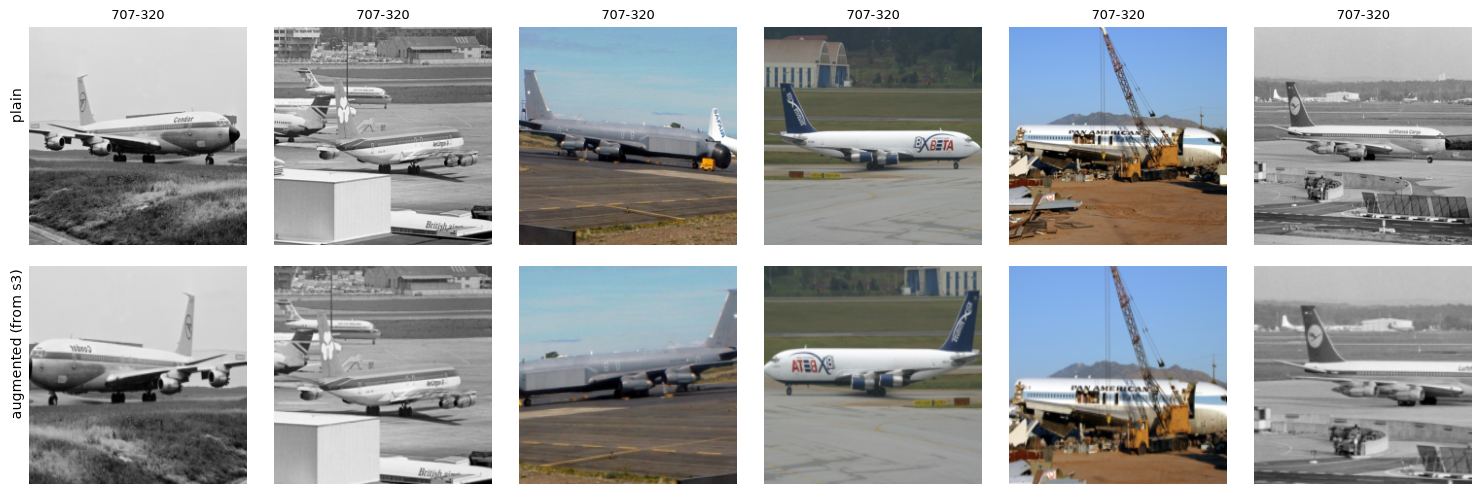

In [7]:
N_CLASSES = 100  # FGVC-Aircraft, annotation_level="variant"
data = get_data(BASE["img_size"]) if TRAIN else None   # the dataset is only needed to train (or to show the images)
if data is None:
    print("TRAIN = False: the sample images are not shown (they need the dataset)")
else:
    CLASSES = data["train"].classes
    assert len(CLASSES) == N_CLASSES
    print(
        f"classes: {N_CLASSES} | train {len(data['train'])} | val {len(data['val'])} | test {len(data['test'])}"
    )

    fix_random(0)
    plain = [preprocess(data["train"].base[i][0], BASE["img_size"]) for i in range(6)]
    crop_flip = T.Compose([
        T.RandomResizedCrop(BASE["img_size"], scale=BASE["crop_scale"], ratio=(3 / 4, 4 / 3), antialias=True),
        T.RandomHorizontalFlip(),
    ])
    rows = [plain, [crop_flip(img) for img in plain]]
    fig, axes = plt.subplots(2, 6, figsize=(15, 5))
    for r, imgs in enumerate(rows):
        for c in range(6):
            axes[r, c].imshow(imgs[c])
            axes[r, c].axis("off")
            if r == 0:
                axes[r, c].set_title(CLASSES[data["train"].y[c]], fontsize=9)
    axes[0, 0].text(-20, 80, "plain", rotation=90, va="center")
    axes[1, 0].text(-20, 80, "augmented (from s3)", rotation=90, va="center")
    plt.tight_layout()
    plt.show()

## The network

A single class covers every configuration:

```
blocks = (n1, n2, n3, n4)

stem      3x3 s2 -> 3x3 -> 3x3 -> maxpool s2          224 -> 56
stage 1   n1 x Block(64)                              56x56
stage 2   n2 x Block(128), the first one stride 2     28x28
stage 3   n3 x Block(256), the first one stride 2     14x14
(stage 4  n4 x Block(512), the first one stride 2      7x7)
head      flatten -> linear            (gap=False)
          global avg pool -> linear    (gap=True)
```

`n x Block(C)` denotes `n` consecutive blocks with `C` output channels. The number of convolutional layers is 3 (stem)
plus 2 per block: 9 for s0–s3, 11 for s4, 19 for `[2,2,2,2]`, 31 for `[3,4,6,1]`.

**Stem.** We reduce the resolution by 4 before the first stage, as in ResNet (He et al., CVPR 2016) and GoogLeNet
(Szegedy et al., CVPR 2015): early layers only detect edges and simple textures, and running the blocks at 56x56
instead of 224x224 is 16 times cheaper. Instead of a single 7x7 convolution we use three 3x3 convolutions with 32, 32
and 64 channels, the "ResNet-C" stem of He et al. (*Bag of Tricks for Image Classification*, CVPR 2019): the same 7x7
receptive field with fewer parameters and two more non-linearities (Simonyan & Zisserman, ICLR 2015). The stem is kept
narrow because it runs at the highest resolution.

**Block.** A block is two 3x3 convolutions, each followed by BatchNorm when enabled. With `residual=True` the block
computes `F(x) + x`: it only has to learn a correction to the identity, and the gradient reaches earlier layers
directly through the skip (He et al., 2016). When a block changes resolution or number of channels, the input goes
through a 1x1 convolution with BN (projection); otherwise it is added unchanged (identity). Plain networks do not
create the projections, so plain and residual versions of a network have almost the same number of parameters.
With one block per stage every skip is a projection; identity skips appear from the second block of a stage on.

In [8]:
def conv_bn(c_in, c_out, k, stride, bn):
    layers = [nn.Conv2d(c_in, c_out, k, stride=stride, padding=k // 2, bias=not bn)]
    if bn:
        layers.append(nn.BatchNorm2d(c_out))
    return nn.Sequential(*layers)


class Block(nn.Module):
    def __init__(self, c_in, c_out, stride, bn, residual):
        super().__init__()
        self.conv1 = conv_bn(c_in, c_out, 3, stride, bn)
        self.conv2 = conv_bn(c_out, c_out, 3, 1, bn)
        self.residual = residual
        if residual and (stride != 1 or c_in != c_out):
            self.skip = conv_bn(c_in, c_out, 1, stride, bn)  # projection
        else:
            self.skip = nn.Identity()

    def forward(self, x):
        out = self.conv2(F.relu(self.conv1(x)))
        if self.residual:
            out = out + self.skip(x)
        return F.relu(out)


class AircraftNet(nn.Module):
    def __init__(self, cfg, n_classes=100):
        super().__init__()
        bn = cfg["batchnorm"]
        c1, c2, c3 = cfg["stem"]
        self.stem = nn.Sequential(
            conv_bn(3, c1, 3, 2, bn),
            nn.ReLU(inplace=True),
            conv_bn(c1, c2, 3, 1, bn),
            nn.ReLU(inplace=True),
            conv_bn(c2, c3, 3, 1, bn),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1),
        )
        layers, c_in = [], c3
        for stage, (c_out, n_blocks) in enumerate(zip(cfg["channels"], cfg["blocks"])):
            for b in range(n_blocks):
                stride = 2 if (b == 0 and stage > 0) else 1
                layers.append(Block(c_in, c_out, stride, bn, cfg["residual"]))
                c_in = c_out
        self.stages = nn.Sequential(*layers)

        if cfg["gap"]:
            self.head = nn.Sequential(
                nn.AdaptiveAvgPool2d(1),
                nn.Flatten(),
                nn.Dropout(cfg["dropout"]),
                nn.Linear(c_in, n_classes),
            )
        else:
            with torch.no_grad():  # size of the last feature map, for the flatten head
                s = self.stages(
                    self.stem(torch.zeros(1, 3, cfg["img_size"], cfg["img_size"]))
                ).shape
            self.head = nn.Sequential(
                nn.Flatten(),
                nn.Dropout(cfg["dropout"]),
                nn.Linear(s[1] * s[2] * s[3], n_classes),
            )

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.head(self.stages(self.stem(x)))


def build_model(cfg, n_classes=100):
    # The network of a configuration: our AircraftNet, or (Part 2) the ResNet-18 of PyTorch pretrained on ImageNet-1K
    # with its 1000-way classifier replaced by Dropout -> Linear(512, n_classes).
    if not cfg.get("pretrained", False):
        return AircraftNet(cfg, n_classes)
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Sequential(
        nn.Dropout(cfg["dropout"]), nn.Linear(model.fc.in_features, n_classes)
    )
    return model


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def count_gflops(model, img_size):
    # Multiply-adds of convolutions and linear layers for one image, x2 = FLOPs.
    macs = 0

    def hook(m, inp, out):
        nonlocal macs
        if isinstance(m, nn.Conv2d):
            macs += (
                out[0].numel()
                * (m.in_channels // m.groups)
                * m.kernel_size[0]
                * m.kernel_size[1]
            )
        elif isinstance(m, nn.Linear):
            macs += m.in_features * m.out_features

    handles = [
        m.register_forward_hook(hook)
        for m in model.modules()
        if isinstance(m, (nn.Conv2d, nn.Linear))
    ]
    with torch.no_grad():
        model.eval()(torch.zeros(1, 3, img_size, img_size))
    for h in handles:
        h.remove()
    return 2 * macs / 1e9

In [ ]:
# the keys that only describe AircraftNet: a pretrained run does not store them
SCRATCH_ONLY_KEYS = ("stem", "channels", "blocks", "batchnorm", "gap", "residual")

## Training

- **Optimizer**: SGD with momentum 0.9; when enabled, weight decay applies to convolution and linear weights only, not
  to BN parameters and biases.
- **Schedule**: linear warmup for 3 epochs, then cosine decay to zero (or one-cycle, where selected by the tuning).
- **Loss**: cross-entropy (with label smoothing where enabled). The validation loss is always plain cross-entropy, so
  that runs with and without smoothing are on the same scale.
- **Model selection**: we keep the epoch with the highest validation accuracy and evaluate the test split once, on
  that checkpoint.

In [11]:
def make_optimizer(model, cfg):
    decay = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]
    return torch.optim.SGD(
        [
            {"params": decay, "weight_decay": cfg["weight_decay"]},
            {"params": no_decay, "weight_decay": 0.0},
        ],
        lr=cfg["lr"],
        momentum=cfg["momentum"],
    )


def lr_at(epoch, cfg):
    if cfg.get("schedule", "cosine") == "onecycle":
        # one-cycle (Smith & Topin, 2019), per epoch: cosine rise from lr/25 to lr over the first 30% of the
        # epochs, then cosine decay to lr/1e4 (the defaults of torch.optim.lr_scheduler.OneCycleLR)
        up = max(round(0.3 * cfg["epochs"]), 1)
        low, high, end = cfg["lr"] / 25, cfg["lr"], cfg["lr"] / 1e4
        if epoch < up:
            return high + (low - high) * (1 + math.cos(math.pi * epoch / up)) / 2
        t = (epoch - up) / max(cfg["epochs"] - up, 1)
        return end + (high - end) * (1 + math.cos(math.pi * t)) / 2
    if epoch < cfg["warmup_epochs"]:
        return cfg["lr"] * (epoch + 1) / cfg["warmup_epochs"]
    progress = (epoch - cfg["warmup_epochs"]) / max(
        cfg["epochs"] - cfg["warmup_epochs"], 1
    )
    return cfg["lr"] * 0.5 * (1 + math.cos(math.pi * progress))


def train_epoch(model, opt, criterion, data, cfg):
    model.train()
    total_loss = torch.zeros((), device=DEVICE)
    correct = torch.zeros((), device=DEVICE)
    n = 0
    for x, y in batches(data["train"], data, cfg, train=True):
        logits = model(x)
        loss = criterion(logits, y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        total_loss += loss.detach().float() * len(y)
        correct += (logits.argmax(1) == y).sum()
        n += len(y)
    return total_loss.item() / n, correct.item() / n


@torch.no_grad()
def evaluate(model, split, data, cfg, return_preds=False):
    model.eval()
    total_loss, correct, preds = 0.0, 0, []
    for x, y in batches(split, data, cfg, train=False):
        logits = model(x)
        total_loss += F.cross_entropy(logits, y, reduction="sum").item()
        p = logits.argmax(1)
        correct += (p == y).sum().item()
        if return_preds:
            preds.append(p.cpu())
    n = len(split)
    out = (total_loss / n, correct / n)
    return out + (torch.cat(preds).tolist(),) if return_preds else out


def fit(cfg, data, verbose=True):
    model = build_model(cfg, N_CLASSES).to(DEVICE)
    opt = make_optimizer(model, cfg)
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
    hist = {
        k: []
        for k in ("train_loss", "train_acc", "val_loss", "val_acc", "lr", "seconds")
    }
    best_acc, best_epoch, best_state, diverged = -1.0, 0, None, False

    for epoch in range(cfg["epochs"]):
        t0 = time.time()
        lr = lr_at(epoch, cfg)
        for g in opt.param_groups:
            g["lr"] = lr
        tr_loss, tr_acc = train_epoch(model, opt, criterion, data, cfg)
        if not math.isfinite(tr_loss):
            diverged = True
            print(f"  diverged at epoch {epoch + 1} (training loss {tr_loss})")
            break
        va_loss, va_acc = evaluate(model, data["val"], data, cfg)
        for k, v in zip(hist, (tr_loss, tr_acc, va_loss, va_acc, lr, time.time() - t0)):
            hist[k].append(v)
        if va_acc > best_acc:
            best_acc, best_epoch = va_acc, epoch + 1
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose and (epoch % 5 == 0 or epoch == cfg["epochs"] - 1):
            print(
                f"  ep {epoch + 1:3d} | lr {lr:.4f} | train loss {tr_loss:.3f} acc {tr_acc:.3f} "
                f"| val loss {va_loss:.3f} acc {va_acc:.3f} | {hist['seconds'][-1]:.1f}s"
            )

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, hist, best_epoch, diverged

## Experiment runner

`run_experiment` trains one configuration (in `results/part1`, or in the directory given by `results_dir`), evaluates its best checkpoint on the test split and stores the
configuration, the per-epoch curves and the test predictions. The runs of the ladder, of the depth x residual comparison and of the recipe search were obtained by calling it for
every configuration at the three learning rates of the sweep (seed 42), and then with two more seeds at the best
learning rate. Note that the seed-42
run of a configuration is the best of three learning rates, hence slightly optimistic; the two additional seeds are
not.

In [12]:
def result_path(name, group, seed, results_dir=None):
    return (results_dir or RESULTS_DIR) / group / f"{name}_seed{seed}.json"


def run_experiment(name, group, note="", results_dir=None, **overrides):
    cfg = {**BASE, **overrides, "name": name, "group": group}
    if cfg.get(
        "pretrained", False
    ):  # the architecture keys of AircraftNet do not describe the pretrained ResNet-18
        cfg = {k: v for k, v in cfg.items() if k not in SCRATCH_ONLY_KEYS}
    out = result_path(name, group, cfg["seed"], results_dir)
    if out.exists() and not RETRAIN:
        run = json.loads(out.read_text())
        if run["config"] == json.loads(
            json.dumps(cfg)
        ):  # same configuration (tuples stored as lists)
            print(
                f"skip {group}/{name}: best val {run['best_val_acc']:.3f} (already trained)"
            )
            return run
        print(
            f"{group}/{name}: configuration changed since the stored run, training again"
        )

    print(f"### {group}/{name}")
    print(
        "    "
        + " | ".join(
            f"{k} {cfg[k]}"
            for k in (
                "lr",
                "weight_decay",
                "label_smoothing",
                "dropout",
                "random_erasing",
                "augment",
                "crop_scale",
                "seed",
                "epochs",
            )
        )
        + f" | schedule {cfg.get('schedule', 'cosine')}"
    )
    fix_random(cfg["seed"])
    data = get_data(cfg["img_size"], cfg.get("pretrained", False))
    t0 = time.time()
    model, hist, best_epoch, diverged = fit(cfg, data)
    minutes = (time.time() - t0) / 60
    if best_epoch:
        test_loss, test_acc, test_pred = evaluate(
            model, data["test"], data, cfg, return_preds=True
        )
    else:  # diverged before the first validation: there is no checkpoint to test
        test_loss, test_acc, test_pred = float("nan"), float("nan"), []

    cpu_model = build_model(cfg, N_CLASSES)
    run = dict(
        name=name,
        group=group,
        seed=cfg["seed"],
        note=note,
        config=cfg,
        history=hist,
        best_val_acc=max(hist["val_acc"], default=0.0),
        best_epoch=best_epoch,
        final_val_acc=hist["val_acc"][-1] if hist["val_acc"] else 0.0,
        final_train_acc=hist["train_acc"][-1] if hist["train_acc"] else 0.0,
        test_acc=test_acc,
        test_loss=test_loss,
        test_pred=test_pred,
        test_true=data["test"].y.cpu().tolist(),
        params=count_params(cpu_model),
        gflops=count_gflops(cpu_model, cfg["img_size"]),
        minutes=minutes,
        device=torch.cuda.get_device_name() if DEVICE.type == "cuda" else str(DEVICE),
        diverged=diverged,
    )
    out.parent.mkdir(parents=True, exist_ok=True)
    out.write_text(json.dumps(run))
    print(
        f"{name}: best val {run['best_val_acc']:.3f} (epoch {best_epoch}) | test {test_acc:.3f} | {minutes:.1f} min"
    )
    return run


def load_group(group, results_dir=None):
    runs = [
        json.loads(p.read_text())
        for p in sorted(((results_dir or RESULTS_DIR) / group).glob("*.json"))
    ]
    return {r["name"]: r for r in runs}


def sweep_runs(runs, name):
    # The seed-42 runs of one configuration of the sweep, keyed by learning rate.
    return {
        r["config"]["lr"]: r
        for n, r in runs.items()
        if n.startswith(f"{name}_lr")
        and r["config"]["lr"] in LR_SWEEP
        and r["seed"] == SEEDS[0]
    }


def best_of(runs, name):
    # The best run (on validation) of one configuration of the sweep; None until every learning rate is trained.
    swept = sweep_runs(runs, name)
    if len(swept) < len(LR_SWEEP):
        return None
    return max(swept.values(), key=lambda r: r["best_val_acc"])


def seed_runs(name, group):
    # Every seed of one configuration at its best learning rate: [seed 42 (from the sweep), seed 43, seed 44].
    best = best_of(load_group(group), name)
    if best is None:
        return []
    lr, others = best["config"]["lr"], load_group(f"{group}_seeds")
    return [best] + [
        others[f"{name}_lr{lr:g}_s{s}"]
        for s in SEEDS[1:]
        if f"{name}_lr{lr:g}_s{s}" in others
    ]


def seed_mean(runs, key="best_val_acc"):
    return float(np.mean([r[key] for r in runs]))


def seed_std(runs, key="best_val_acc"):
    return (
        float(np.std([r[key] for r in runs], ddof=1)) if len(runs) > 1 else float("nan")
    )


def finalists(n=TUNE_N):
    # The n networks of the grid with the highest mean validation accuracy over the seeds.
    done = {name: seed_runs(name, "depth_residual") for name, _ in GRID}
    if any(len(r) < len(SEEDS) for r in done.values()):
        return None
    return sorted(done, key=lambda name: -seed_mean(done[name]))[:n]


def simplicity(name):
    # Sort key: fewer blocks first, then plain before residual.
    over = dict(GRID)[name]
    return (sum(over["blocks"]), over["residual"])


def random_configs():
    # The N_RANDOM configurations of the random search: drawn once, identical for every network.
    rng = np.random.RandomState(SEARCH_SEED)
    configs, seen = [], set()
    while len(configs) < N_RANDOM:
        cfg = {k: v[rng.randint(len(v))] for k, v in SEARCH_SPACE.items()}
        key = json.dumps(cfg)
        if key not in seen:
            seen.add(key)
            if cfg["schedule"] == "cosine":
                del cfg[
                    "schedule"
                ]  # cosine is the default: keep the stored config minimal
            configs.append(cfg)
    return configs


def run_overrides(run):
    # The overrides that reproduce a stored run (everything but its name, group and seed).
    return {
        k: v for k, v in run["config"].items() if k not in ("name", "group", "seed")
    }


def tuning_runs(name):
    # Every seed-42 run of the recipe search (grid + random) of one network, keyed by run name.
    runs = {**load_group("tune_grid"), **load_group("tune_random")}
    return {n: r for n, r in runs.items() if n.startswith(name + "_")}


def best_grid_point(name):
    grid = {
        n: r for n, r in load_group("tune_grid").items() if n.startswith(name + "_")
    }
    if len(grid) < len(TUNE_LRS) * len(TUNE_WDS):
        return None
    best = max(grid.values(), key=lambda r: r["best_val_acc"])
    return best["config"]["lr"], best["config"]["weight_decay"]


def top_configs(name):
    # The TOP_K best runs of the search of one network (seed 42).
    runs = tuning_runs(name)
    return sorted(runs.values(), key=lambda r: -r["best_val_acc"])[:TOP_K]


def confirmed(name):
    # {run name: [seed 42, 43, 44]} for the TOP_K configurations of one network.
    seeds = load_group("tune_seeds")
    return {
        r["name"]: [r]
        + [
            seeds[f"{r['name']}_s{s}"]
            for s in SEEDS[1:]
            if f"{r['name']}_s{s}" in seeds
        ]
        for r in top_configs(name)
    }


def best_tuned(name):
    # (configuration name, [runs over the seeds]) of the best configuration of the recipe search of one network.
    conf = {n: runs for n, runs in confirmed(name).items() if len(runs) == len(SEEDS)}
    if not conf:
        return None
    best = max(conf, key=lambda n: seed_mean(conf[n]))
    return best, conf[best]


def long_runs(name):
    # The longer trainings of one network, over the seeds.
    group = load_group("long")
    return [
        group[f"{name}_ep{LONG_EPOCHS}_s{s}"]
        for s in SEEDS
        if f"{name}_ep{LONG_EPOCHS}_s{s}" in group
    ]

initial loss 4.716  (expected ~4.61)
tiny subset: train acc 1.00  (expected ~1.00)


## The ladder: s0 -> s4

What each step is expected to show:

- **s0 (plain VGG) memorizes.** It has 6.2M parameters for 3,334 training images, 5M of them in the flatten head: the
  last feature map is flattened into 50,176 features, more than the number of training images, so a linear classifier
  on top can separate any labelling of them. With no augmentation and no regularization, training accuracy reaches
  100% while validation accuracy stalls and validation loss rises. Standard CNNs can even fit randomly shuffled labels
  (Zhang et al., ICLR 2017).
- **s1, BatchNorm** (Ioffe & Szegedy, ICML 2015) normalizes the activations of every layer, which makes optimization
  better behaved and more tolerant to the learning rate.
- **s2, global average pooling** (Lin et al., *Network in Network*, ICLR 2014) reduces each channel of the last
  feature map to one number: the 5M-weight head becomes a 26k-weight one.
- **s3, crop and flip** show a different version of every image at every epoch, so the training set can no longer be
  memorized exactly.
- **s4, a 4th stage** adds capacity and receptive field once the network is regularized.

## Depth x residual

We replicate at small scale the central experiment of He et al. (CVPR 2016): **identical plain and residual networks
at increasing depth**. All six networks are s4 (BatchNorm, GAP, crop and flip, four stages of 64 to 512 channels) with
a different number of blocks per stage, with and without skip connections:

| blocks per stage | convolutional layers | parameters | motivation |
|---|---|---|---|
| `[1,1,1,1]` | 11 | 4.8M | s4 itself, the shallow reference |
| `[2,2,2,2]` | 19 | 11.1M | the stage layout of ResNet-18; at this depth He et al. find plain and residual networks on par |
| `[3,4,6,1]` | 31 | 11.8M | the layout of ResNet-34 with a single block in the last stage; at 34 layers He et al. find the plain network *worse* than its shallower version and the residual one better |

We use `[3,4,6,1]` rather than the full `[3,4,6,3]` (21.4M parameters) because a 512-channel block alone costs 4.7M
parameters: the additional depth goes into the first three stages, where it is cheap.

**Reading the results.** Within a depth, plain and residual networks differ only by the skip connections. Across
depths more changes than depth (`[3,4,6,1]` also redistributes capacity and doubles the compute), so a drop of the
plain network with depth is meaningful only if the residual network with the same layout does not drop. The
signature of degradation is in the *training* accuracy: a network that is harder to optimize fits its training set
worse, whereas an overfitting one fits it better.

### Seeds

Run-to-run variation (initialization, data order, augmentation) is easily 1–2 points on 3,333 validation images,
comparable to the differences between several networks. We train every network with two more seeds at its best
learning rate and compare means.

## The training recipe

We now regularize the three best networks of the depth x residual experiment and tune their training recipe. The
recipe combines standard techniques from lecture 6:

| component | effect | reference |
|---|---|---|
| weight decay (not on BN/bias) | penalizes large weights | l2 regularization, lecture 6 |
| label smoothing | target of 1−ε on the true class, ε spread over the others: the network is not pushed towards infinite confidence | Szegedy et al., CVPR 2016 |
| dropout before the classifier | randomly drops features during training; placed between global pooling and the last linear layer | Srivastava et al., JMLR 2014 |
| random erasing | hides a random rectangle of the image | Zhong et al., AAAI 2020 |
| minimum crop area | smaller crops show parts of the aircraft at a larger scale (multi-scale training) | lecture 6 |
| one-cycle schedule | the learning rate rises over the first 30% of training, then decays | Smith & Topin, 2019 |

We tune it in three steps, following the hyperparameter search of lecture 6:

1. **Grid search on learning rate x weight decay** (log-spaced), the two most influential parameters: learning rate
   0.1 and 0.05, weight decay from 1e-4 to 1e-2. During this step the other parameters are fixed (label smoothing
   0.1, dropout 0.2, random erasing 0.25, minimum crop 50%, cosine schedule). The grid initially stopped at 2e-3,
   which turned out to be the best value for two networks; since an optimum at the edge of a grid may lie beyond it,
   we extended the grid until accuracy decreased.
2. **Random search on the other parameters** (Bergstra & Bengio, JMLR 2012), at the best learning rate and weight
   decay of each network. A full grid on these five parameters would require 216 runs per network; we draw 12
   configurations once and train the same 12 on every network.
3. **Confirmation with seeds.** The best of many single runs is partly the luckiest one, so we retrain the two best
   configurations of each network with two more seeds and compare means.

| parameter | values | note |
|---|---|---|
| label smoothing | 0, 0.05, 0.1, 0.2 | |
| dropout | 0, 0.2, 0.5 | dropout is not used in ResNets, for its unclear interaction with BatchNorm (lecture 6), so 0 is a real candidate |
| random erasing | p = 0, 0.25, 0.5 | the original papers use 0.5 |
| minimum crop area | 25%, 35%, 50% | |
| schedule | cosine with warmup, one-cycle | |

We leave out Mixup, CutMix, TrivialAugment and stochastic depth, which make the training task much harder and pay off
only with schedules much longer than 70 epochs, and the exponential moving average of the weights, which mainly helps
at the end of long trainings: they are candidates for a final, longer training.

**Networks.** We tune `plain_2222` and `res_3461`, the two best networks, and `res_2222`, the third: it has the
highest training accuracy of the experiment, i.e. it overfits the most, so it is the network a stronger regularization
can help most. We exclude `plain_3461`, which does not fit its training set (an optimization problem that
regularization cannot fix), and the two 11-layer networks, which trail the best ones by 5–9 points. All three networks
receive the same tuning budget, so that the final comparison is fair.

**Selection rule.** For each network we take its best configuration by mean validation accuracy over the seeds; the
final network is the one with the highest mean, and if the two best are within one standard deviation of each other,
the simpler one.

**Limitation.** The search proceeds in two stages: the learning rate and weight decay are chosen with fixed values of
the other parameters, so they are not guaranteed to be jointly optimal with the configuration found by the random
search.

## Longer training

The training recipe was tuned with a budget of 70 epochs, and the best runs of the three tuned networks reach their
best validation accuracy in the last epochs, with a training accuracy still around 90%: they are still improving
when training stops. We therefore train the three networks again for **150 epochs**, each with its own best
configuration and **no other change** — no additional regularization or augmentation — with three seeds each. The
one-cycle schedule is defined in fractions of the training, so it stretches with the number of epochs.

Since the recipe was tuned for 70 epochs, a longer training gives the networks more time to overfit: we check that
the gap between training and validation accuracy does not grow. The final model is selected with the same rule as
before, now at 150 epochs.

In [20]:
# [run]
# The final model: res_3461 with the best configuration of its recipe search (cfg05), trained for LONG_EPOCHS epochs
FINAL_NAME = "res_3461"
FINAL_CONFIG = {
    **dict(GRID)[FINAL_NAME],
    **RECIPE,
    "lr": 0.05,
    "weight_decay": 5e-3,
    "label_smoothing": 0.2,
    "dropout": 0.0,
    "random_erasing": 0.25,
    "crop_scale": (0.5, 1.0),
    "schedule": "onecycle",
    "epochs": LONG_EPOCHS,
}
if TRAIN:
    for seed in SEEDS:
        run_experiment(
            f"{FINAL_NAME}_ep{LONG_EPOCHS}_s{seed}",
            "long",
            note=f"cfg05, {LONG_EPOCHS} epochs",
            **{**FINAL_CONFIG, "seed": seed},
        )

plain_2222: plain_2222_cfg05, 150 epochs
skip long/plain_2222_ep150_s42: best val 0.728 (already trained)
skip long/plain_2222_ep150_s43: best val 0.719 (already trained)
skip long/plain_2222_ep150_s44: best val 0.725 (already trained)
res_3461: res_3461_cfg05, 150 epochs
skip long/res_3461_ep150_s42: best val 0.746 (already trained)
skip long/res_3461_ep150_s43: best val 0.743 (already trained)
skip long/res_3461_ep150_s44: best val 0.732 (already trained)
res_2222: res_2222_cfg05, 150 epochs
skip long/res_2222_ep150_s42: best val 0.705 (already trained)
skip long/res_2222_ep150_s43: best val 0.706 (already trained)
skip long/res_2222_ep150_s44: best val 0.713 (already trained)


## Results

All tables and plots below are computed from the stored runs.

In [21]:
# Categorical colours in a fixed order (one per run inside a plot)
COLORS = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
plt.rcParams.update(
    {
        "axes.prop_cycle": plt.cycler(color=COLORS),
        "lines.linewidth": 2,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)


def summary(runs):
    # One row per run (single seed).
    rows = [
        dict(
            run=n,
            lr=r["config"]["lr"],
            params_M=r["params"] / 1e6,
            best_val=r["best_val_acc"],
            best_epoch=r["best_epoch"],
            final_train=r["final_train_acc"],
            gap=r["final_train_acc"] - r["final_val_acc"],
            test=r["test_acc"],
            minutes=r["minutes"],
        )
        for n, r in runs.items()
    ]
    return (
        pd.DataFrame(rows)
        .set_index("run")
        .style.format(
            {
                "lr": "{:g}",
                "params_M": "{:.2f}",
                "best_val": "{:.3f}",
                "final_train": "{:.3f}",
                "gap": "{:+.3f}",
                "test": "{:.3f}",
                "minutes": "{:.1f}",
            }
        )
    )


def seed_summary(groups):
    # One row per configuration, mean ± std over the seeds. groups: {label: [runs]}
    rows = [
        dict(
            run=label,
            lr=runs[0]["config"]["lr"],
            seeds=len(runs),
            params_M=runs[0]["params"] / 1e6,
            val_mean=seed_mean(runs),
            val_std=seed_std(runs),
            test_mean=seed_mean(runs, "test_acc"),
            test_std=seed_std(runs, "test_acc"),
            train_mean=seed_mean(runs, "final_train_acc"),
        )
        for label, runs in groups.items()
        if runs
    ]
    return (
        pd.DataFrame(rows)
        .set_index("run")
        .style.format(
            {
                "lr": "{:g}",
                "params_M": "{:.2f}",
                "val_mean": "{:.3f}",
                "val_std": "{:.3f}",
                "test_mean": "{:.3f}",
                "test_std": "{:.3f}",
                "train_mean": "{:.3f}",
            }
        )
    )


def plot_curves(runs, title=""):
    # Validation accuracy, validation loss (plain CE) and training accuracy against the epoch.
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for i, (name, r) in enumerate(runs.items()):
        h = r["history"]
        ep = range(1, len(h["val_acc"]) + 1)
        c = COLORS[i % len(COLORS)]
        axes[0].plot(ep, h["val_acc"], color=c, label=name)
        if r["best_epoch"]:
            axes[0].plot(r["best_epoch"], r["best_val_acc"], "o", color=c, markersize=7)
        axes[1].plot(ep, h["val_loss"], color=c, label=name)
        axes[2].plot(ep, h["train_acc"], color=c, label=name)
    for ax, t in zip(
        axes,
        (
            "validation accuracy (dot = best epoch)",
            "validation loss (plain CE)",
            "training accuracy",
        ),
    ):
        ax.set_title(t)
        ax.set_xlabel("epoch")
    axes[0].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

### The ladder

Each step at its best learning rate (one seed).

Every step improves validation accuracy, from **18.5%** (s0) to **52.6%** (s4): BatchNorm adds 11.7 points, global
average pooling 13.3, crop and flip 4.2, the fourth stage 4.9. The curves show the mechanism: s0–s2 reach 100%
training accuracy, i.e. they memorize the training set, and the validation loss of s0 rises while its training loss
goes to zero. From s3 on, augmentation keeps the training accuracy below 100% and the train–validation gap shrinks.

,lr,params_M,best_val,best_epoch,final_train,gap,test,minutes
run,,,,,,,,
s0_vgg,0.01,6.23,0.185,29,1.000,+0.815,0.189,0.6
s1_bn,0.01,6.23,0.302,37,1.000,+0.699,0.299,0.7
s2_gap,0.1,1.24,0.435,46,1.000,+0.567,0.440,0.7
s3_aug,0.1,1.24,0.477,66,0.947,+0.472,0.477,0.7
s4_stage4,0.05,4.80,0.526,70,0.980,+0.454,0.507,0.8


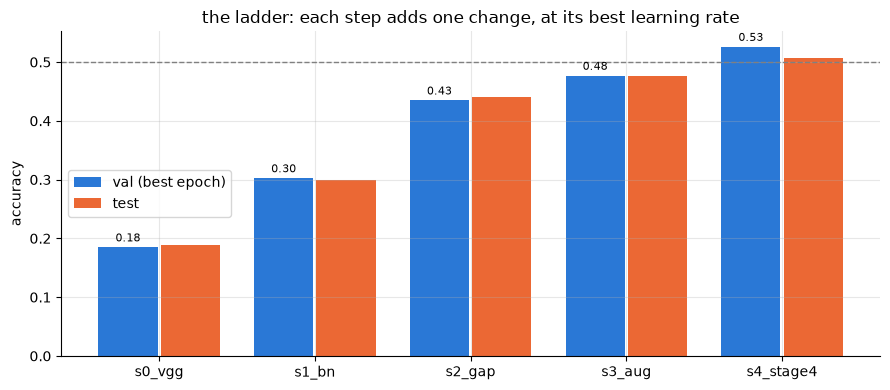

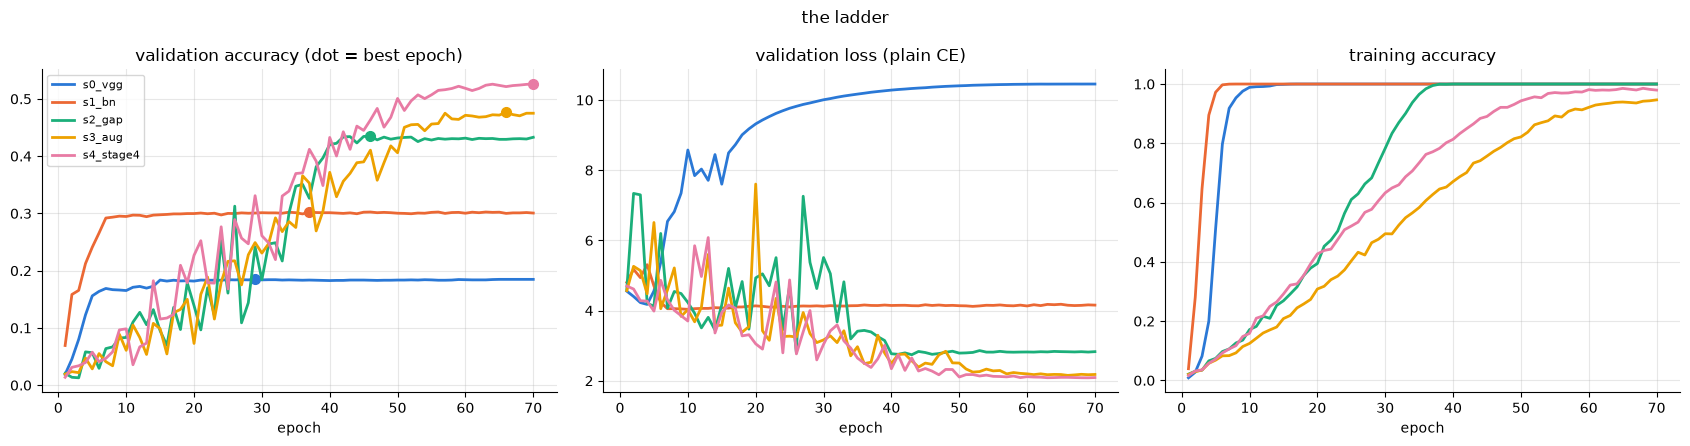

In [22]:
ladder = load_group("ladder")
steps = {n: best_of(ladder, n) for n, _ in LADDER}
steps = {n: r for n, r in steps.items() if r}
if steps:
    display(summary(steps))

    names = list(steps)
    xs = np.arange(len(names))
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(
        xs - 0.2,
        [steps[n]["best_val_acc"] for n in names],
        0.38,
        label="val (best epoch)",
        color=COLORS[0],
    )
    ax.bar(
        xs + 0.2,
        [steps[n]["test_acc"] for n in names],
        0.38,
        label="test",
        color=COLORS[1],
    )
    for x_, n in zip(xs, names):
        ax.text(
            x_ - 0.2,
            steps[n]["best_val_acc"] + 0.01,
            f"{steps[n]['best_val_acc']:.2f}",
            ha="center",
            fontsize=8,
        )
    ax.set_xticks(xs, names)
    ax.set_ylabel("accuracy")
    ax.axhline(0.5, ls="--", c="gray", lw=1)
    ax.legend()
    ax.set_title("the ladder: each step adds one change, at its best learning rate")
    plt.tight_layout()
    plt.show()

    plot_curves(steps, "the ladder")

### Sensitivity to the learning rate

Without BatchNorm (s0) the network diverges at lr 0.1 and reaches only 4% at 0.05; with BatchNorm (s1) it trains at
every learning rate and is 11.7 points better at its best one (0.01). After global average pooling the best learning
rate moves to 0.05–0.1 and 0.01 becomes clearly worse: a single learning rate for every step would have penalized
some steps.

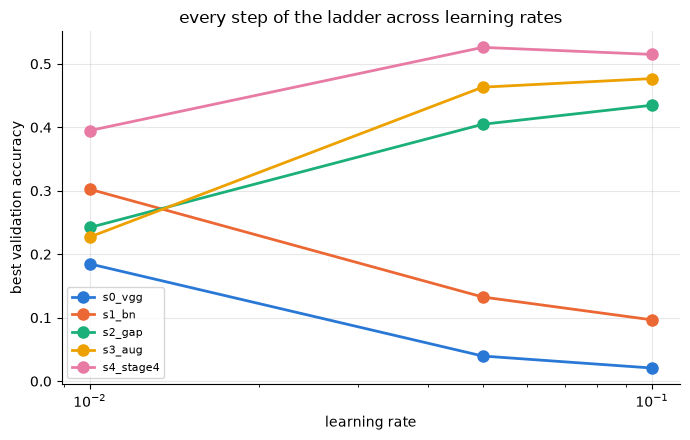

In [23]:
if ladder:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for i, (name, _) in enumerate(LADDER):
        swept = sweep_runs(ladder, name)
        if swept:
            lrs = sorted(swept)
            ax.plot(
                lrs,
                [swept[lr]["best_val_acc"] for lr in lrs],
                "o-",
                color=COLORS[i],
                label=name,
                markersize=8,
            )
    ax.set_xscale("log")
    ax.set_xlabel("learning rate")
    ax.set_ylabel("best validation accuracy")
    ax.set_title("every step of the ladder across learning rates")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

### Depth x residual

Mean ± standard deviation over three seeds, each network at its best learning rate; the curves are the seed-42 runs.

- **Degradation.** Going from 19 to 31 layers, the plain network loses 8.3 points (55.9% -> 47.6%) and its *training*
  accuracy drops too (97.5% -> 91.9%): the deeper plain network is harder to optimize, the degradation problem of He et
  al. The residual network improves with depth at every step (46.9% -> 52.2% -> 54.6%) and keeps fitting its training
  set.
- **Shallow networks.** At 11 and 19 layers the residual networks are about 4 points *worse* than the plain ones,
  well beyond the seed noise. They also reach a higher training accuracy (99% vs 97–98%): without regularization, the
  ease of fitting that skip connections provide turns into more overfitting on 33 images per class. The training
  recipe below tests this hypothesis.

,lr,seeds,params_M,val_mean,val_std,test_mean,test_std,train_mean
run,,,,,,,,
plain_1111,0.05,3,4.80,0.513,0.011,0.501,0.014,0.984
res_1111,0.1,3,4.98,0.469,0.004,0.460,0.004,0.994
plain_2222,0.05,3,11.07,0.559,0.014,0.551,0.012,0.975
res_2222,0.05,3,11.25,0.522,0.012,0.519,0.003,0.991
plain_3461,0.01,3,11.74,0.476,0.014,0.482,0.013,0.919
res_3461,0.05,3,11.91,0.546,0.003,0.545,0.008,0.987


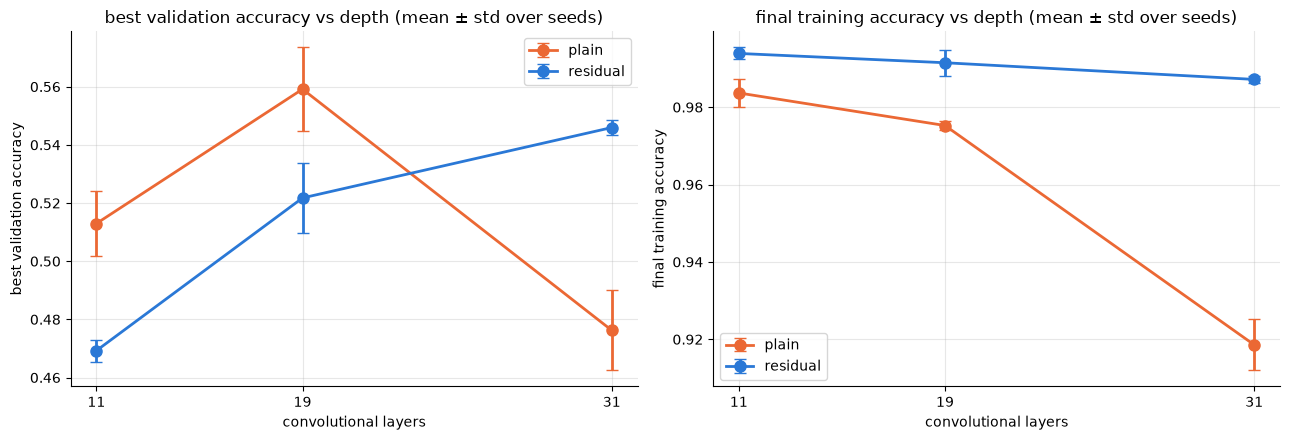

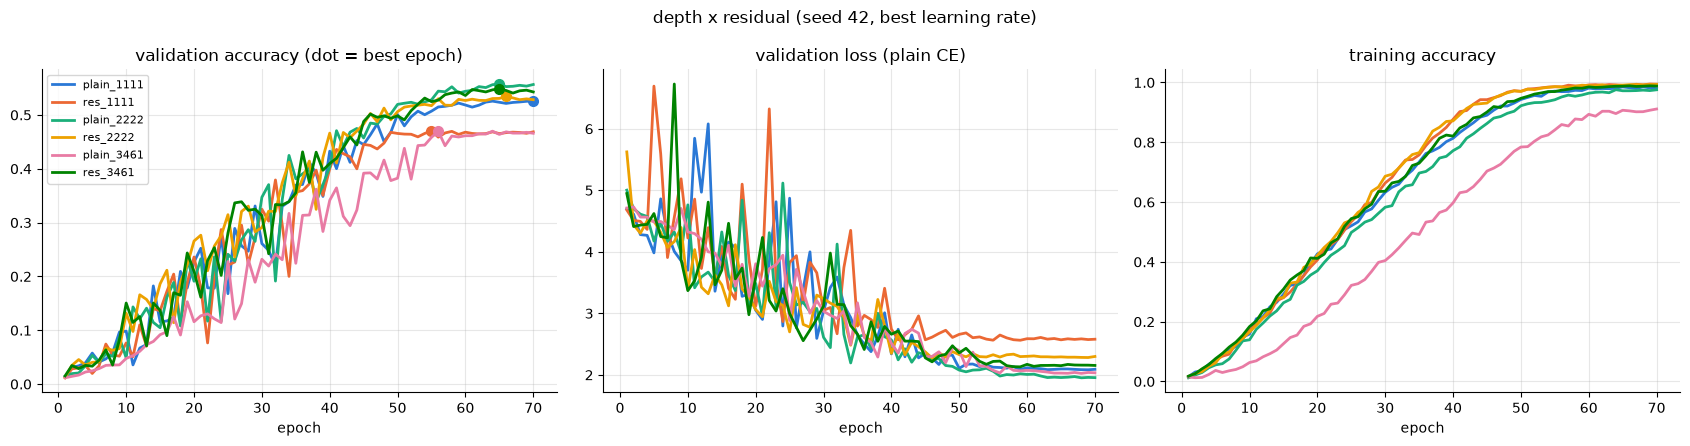

In [24]:
grid_runs = {n: seed_runs(n, "depth_residual") for n, _ in GRID}
grid_runs = {n: r for n, r in grid_runs.items() if r}
if grid_runs:
    display(seed_summary(grid_runs))

    convs = {n: 3 + 2 * sum(dict(GRID)[n]["blocks"]) for n in grid_runs}
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for kind, label, c in (
        ("plain", "plain", COLORS[1]),
        ("res", "residual", COLORS[0]),
    ):
        names = [n for n in grid_runs if n.startswith(kind + "_")]
        if not names:
            continue
        for ax, key in zip(axes, ("best_val_acc", "final_train_acc")):
            ax.errorbar(
                [convs[n] for n in names],
                [seed_mean(grid_runs[n], key) for n in names],
                yerr=[np.nan_to_num(seed_std(grid_runs[n], key)) for n in names],
                fmt="o-",
                color=c,
                capsize=4,
                markersize=8,
                label=label,
            )
    for ax, t in zip(axes, ("best validation accuracy", "final training accuracy")):
        ax.set_xlabel("convolutional layers")
        ax.set_ylabel(t)
        ax.set_xticks(sorted(set(convs.values())))
        ax.set_title(f"{t} vs depth (mean ± std over seeds)")
        ax.legend()
    plt.tight_layout()
    plt.show()

    plot_curves(
        {n: r[0] for n, r in grid_runs.items()},
        "depth x residual (seed 42, best learning rate)",
    )

### Recipe tuning

**Grid search** (seed 42). Accuracy increases with weight decay up to 2e-3 for `plain_2222` and 5e-3 for both
residual networks, then drops sharply at 1e-2, so the optimum lies inside the grid. The residual networks, which fit
their training set more easily, need the stronger regularization. With strong weight decay, lr 0.05 is better than
0.1.

In [25]:
names = finalists(TUNE_N) or []
grid_runs_t = load_group("tune_grid")
for name in names:
    runs = {n: r for n, r in grid_runs_t.items() if n.startswith(name + "_")}
    if runs:
        table = pd.DataFrame(
            {
                f"wd {wd:g}": {
                    f"lr {lr:g}": runs.get(f"{name}_lr{lr:g}_wd{wd:g}", {}).get(
                        "best_val_acc", np.nan
                    )
                    for lr in TUNE_LRS
                }
                for wd in TUNE_WDS
            }
        )
        print(name)
        display(table.style.format("{:.3f}").highlight_max(axis=None, color="#cde2fb"))

plain_2222


,wd 0.0001,wd 0.0005,wd 0.001,wd 0.002,wd 0.005,wd 0.01
lr 0.1,0.570,0.560,0.562,0.525,0.422,0.240
lr 0.05,0.568,0.597,0.604,0.610,0.551,0.447


res_3461


,wd 0.0001,wd 0.0005,wd 0.001,wd 0.002,wd 0.005,wd 0.01
lr 0.1,0.576,0.583,0.620,0.601,0.569,0.409
lr 0.05,0.559,0.590,0.604,0.618,0.625,0.553


res_2222


,wd 0.0001,wd 0.0005,wd 0.001,wd 0.002,wd 0.005,wd 0.01
lr 0.1,0.524,0.569,0.601,0.605,0.570,0.395
lr 0.05,0.514,0.543,0.563,0.593,0.619,0.569


**Random search** (seed 42), sorted by the mean over the three networks; the plot shows, for each parameter value, the
accuracy of the runs that used it.

The ranking is consistent across networks. The same configuration (`cfg05`: label smoothing 0.2, no dropout, random
erasing 0.25, minimum crop 50%, one-cycle) is the best or second best for all three. The one-cycle schedule appears in
the best configurations, no dropout in the two best, and random erasing at 0.5 in all of the worst ones.

,label_smoothing,dropout,random_erasing,crop_min,schedule,plain_2222,res_3461,res_2222,mean
cfg,,,,,,,,,
cfg05,0.200000,0.000000,0.250000,0.500000,onecycle,0.618,0.644,0.647,0.636
cfg11,0.100000,0.000000,0.000000,0.350000,onecycle,0.615,0.651,0.622,0.629
cfg08,0.050000,0.200000,0.000000,0.500000,cosine,0.593,0.630,0.627,0.617
cfg10,0.000000,0.000000,0.000000,0.350000,onecycle,0.595,0.633,0.616,0.615
cfg00,0.000000,0.200000,0.000000,0.350000,onecycle,0.603,0.629,0.611,0.614
cfg03,0.200000,0.500000,0.000000,0.350000,onecycle,0.598,0.612,0.623,0.611
cfg01,0.050000,0.500000,0.000000,0.500000,cosine,0.586,0.605,0.611,0.600
cfg04,0.050000,0.200000,0.000000,0.350000,cosine,0.559,0.624,0.606,0.596
cfg07,0.200000,0.200000,0.500000,0.250000,onecycle,0.559,0.546,0.566,0.557


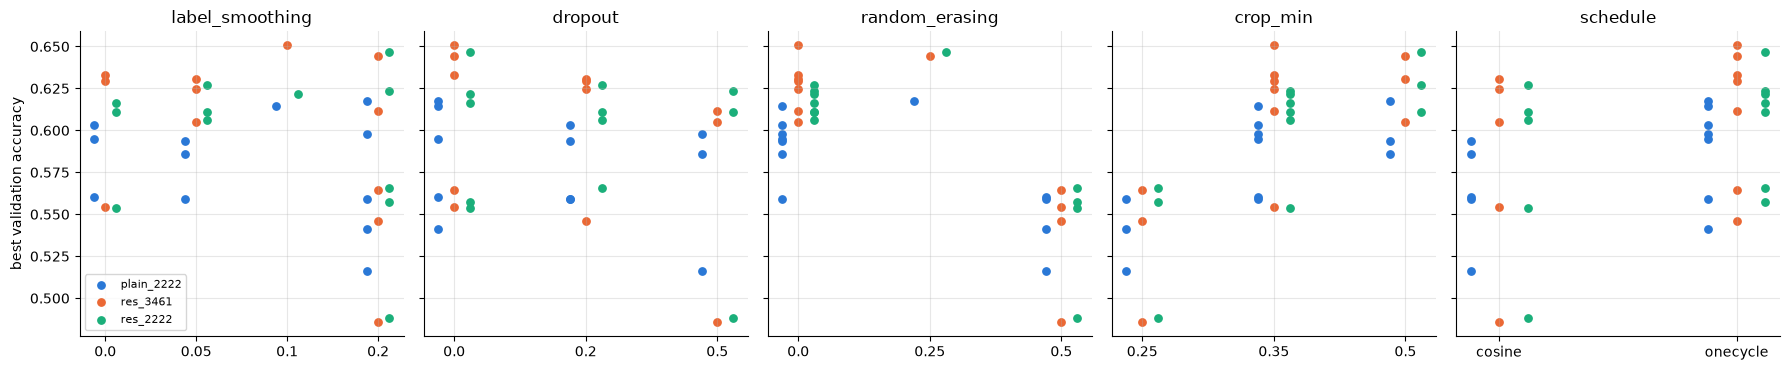

In [26]:
random_runs = load_group("tune_random")
configs = random_configs()
if names and random_runs:
    rows = []
    for i, c in enumerate(configs):
        row = dict(
            cfg=f"cfg{i:02d}",
            label_smoothing=c["label_smoothing"],
            dropout=c["dropout"],
            random_erasing=c["random_erasing"],
            crop_min=c["crop_scale"][0],
            schedule=c.get("schedule", "cosine"),
        )
        for name in names:
            r = random_runs.get(f"{name}_cfg{i:02d}")
            row[name] = r["best_val_acc"] if r else np.nan
        rows.append(row)
    table = pd.DataFrame(rows).set_index("cfg")
    table["mean"] = table[names].mean(axis=1)
    display(
        table.sort_values("mean", ascending=False).style.format(
            {n: "{:.3f}" for n in names + ["mean"]}
        )
    )

    params = ["label_smoothing", "dropout", "random_erasing", "crop_min", "schedule"]
    fig, axes = plt.subplots(1, len(params), figsize=(18, 3.8), sharey=True)
    for ax, p in zip(axes, params):
        values = sorted(table[p].unique(), key=str)
        for j, name in enumerate(names):
            for k, v in enumerate(values):
                ys = table.loc[table[p] == v, name].dropna()
                ax.scatter(
                    [k + (j - 1) * 0.12] * len(ys),
                    ys,
                    color=COLORS[j],
                    s=28,
                    label=name if (p == params[0] and k == 0) else None,
                )
        ax.set_xticks(range(len(values)), [str(v) for v in values])
        ax.set_title(p)
    axes[0].set_ylabel("best validation accuracy")
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

**Confirmation and final choice**: the two best configurations of each network, mean ± standard deviation over
three seeds; summary of the best one per network:

| network | best configuration | validation | test |
|---|---|---|---|
| `res_3461` | `cfg05`, lr 0.05, wd 5e-3 | 64.2 ± 0.3 | 64.7 ± 0.5 |
| `res_2222` | `cfg05`, lr 0.05, wd 5e-3 | 64.1 ± 0.7 | 64.0 ± 0.3 |
| `plain_2222` | `cfg05`, lr 0.05, wd 2e-3 | 63.0 ± 1.1 | 63.1 ± 0.8 |

All three networks select the same configuration, `cfg05`: label smoothing 0.2, random erasing 0.25, crops of at least
50% of the image, no dropout and a one-cycle schedule peaking at lr 0.05 (weight decay 5e-3 for the residual networks,
2e-3 for the plain one). At 70 epochs the two residual networks are within 0.1 points, far less than one standard
deviation, so our rule would select the simpler one, `res_2222`. Since all three networks were still improving at the
end of training, we repeat the selection after a longer training (next section).

Tuning confirms the hypothesis of the depth x residual experiment: without regularization the 19-layer residual
network was 3.7 points *worse* than the plain one; with a tuned recipe it is 1.1 points *better*. The ease of fitting
given by the skip connections turns into accuracy once overfitting is controlled.

,lr,seeds,params_M,val_mean,val_std,test_mean,test_std,train_mean
run,,,,,,,,
plain_2222 | cfg05,0.05,3,11.07,0.630,0.011,0.631,0.008,0.892
plain_2222 | cfg11,0.05,3,11.07,0.608,0.006,0.599,0.010,0.928
res_3461 | cfg11,0.05,3,11.91,0.638,0.012,0.633,0.011,0.949
res_3461 | cfg05,0.05,3,11.91,0.642,0.003,0.647,0.005,0.905
res_2222 | cfg05,0.05,3,11.25,0.641,0.007,0.640,0.003,0.931
res_2222 | cfg08,0.05,3,11.25,0.627,0.001,0.623,0.010,0.978


res_3461    best config res_3461_cfg05: val 0.642 ± 0.003 | test 0.647 ± 0.005
res_2222    best config res_2222_cfg05: val 0.641 ± 0.007 | test 0.640 ± 0.003
plain_2222  best config plain_2222_cfg05: val 0.630 ± 0.011 | test 0.631 ± 0.008
-> a tie (0.001 <= 0.007): the simpler network, res_2222
final configuration: {'img_size': 224, 'augment': True, 'crop_scale': [0.5, 1.0], 'stem': [32, 32, 64], 'channels': [64, 128, 256, 512], 'blocks': [2, 2, 2, 2], 'batchnorm': True, 'gap': True, 'residual': True, 'dropout': 0.0, 'epochs': 70, 'batch_size': 64, 'lr': 0.05, 'momentum': 0.9, 'weight_decay': 0.005, 'label_smoothing': 0.2, 'random_erasing': 0.25, 'warmup_epochs': 3, 'schedule': 'onecycle'}


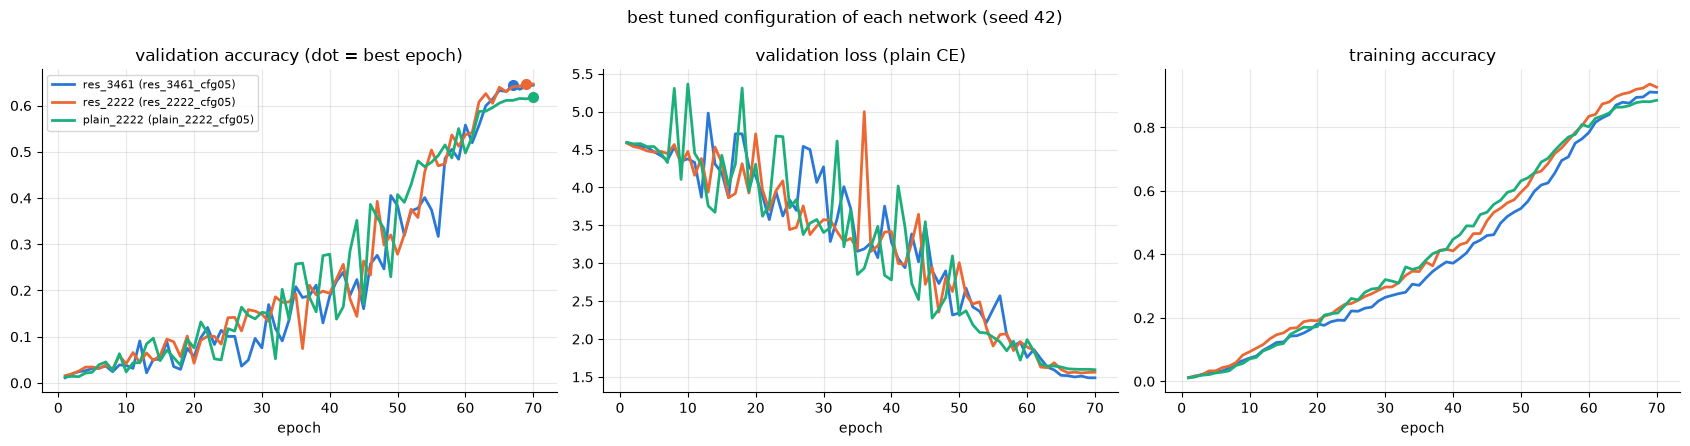

In [27]:
if names:
    groups, best_per_net = {}, {}
    for name in names:
        conf = {
            n: runs for n, runs in confirmed(name).items() if len(runs) == len(SEEDS)
        }
        for n, runs in conf.items():
            groups[f"{name} | {n.removeprefix(name + '_')}"] = runs
        if conf:
            best = max(conf, key=lambda n: seed_mean(conf[n]))
            best_per_net[name] = (best, conf[best])
    if groups:
        display(seed_summary(groups))

    if len(best_per_net) == len(names):
        ranked = sorted(best_per_net, key=lambda n: -seed_mean(best_per_net[n][1]))
        for n in ranked:
            cfg_name, runs = best_per_net[n]
            print(
                f"{n:11s} best config {cfg_name}: val {seed_mean(runs):.3f} ± {seed_std(runs):.3f} | "
                f"test {seed_mean(runs, 'test_acc'):.3f} ± {seed_std(runs, 'test_acc'):.3f}"
            )
        first, second = ranked[0], ranked[1]
        diff = seed_mean(best_per_net[first][1]) - seed_mean(best_per_net[second][1])
        noise = max(seed_std(best_per_net[first][1]), seed_std(best_per_net[second][1]))
        if diff > noise:
            final = first
            print(
                f"-> {first}: better by {diff:.3f}, more than one standard deviation ({noise:.3f})"
            )
        else:
            final = min((first, second), key=simplicity)
            print(f"-> a tie ({diff:.3f} <= {noise:.3f}): the simpler network, {final}")
        print("final configuration:", run_overrides(best_per_net[final][1][0]))
        plot_curves(
            {f"{n} ({best_per_net[n][0]})": best_per_net[n][1][0] for n in ranked},
            "best tuned configuration of each network (seed 42)",
        )

### Longer training and the final model

Each tuned network with its best configuration, at 70 and at 150 epochs (mean ± standard deviation over three
seeds), and the selection rule applied at 150 epochs. The curves compare 70 and 150 epochs for every network
(seed 42).

| network | 70 epochs (val) | 150 epochs (val) | 150 epochs (test) | gain | train accuracy at 150 |
|---|---|---|---|---|---|
| `res_3461` | 64.2 ± 0.3 | **74.0 ± 0.7** | **74.2 ± 0.2** | +9.8 | 98.2% |
| `plain_2222` | 63.0 ± 1.1 | 72.4 ± 0.5 | 72.0 ± 0.6 | +9.4 | 97.8% |
| `res_2222` | 64.1 ± 0.7 | 70.8 ± 0.4 | 71.2 ± 0.6 | +6.7 | 98.5% |

- **Longer training adds 7–10 points** to every network, with no other change: at 70 epochs the networks were stopped
  too early. With the one-cycle schedule the learning rate is still high in the middle of the longer training, so
  the validation accuracy stays low until the final decay; the comparison is meaningful at the end of training.
- **Overfitting does not increase.** The gap between training and validation accuracy of `res_3461` goes from 26 points
  at 70 epochs to 24 at 150: the recipe tuned for 70 epochs still controls overfitting with a longer budget.
- **The ranking changes.** At 150 epochs `res_3461` is 1.6 points better than the second network, more than twice the
  run-to-run noise, so by our selection rule it is the final model. The deepest residual network benefits most from
  the additional training; training only the winner at 70 epochs (`res_2222`) longer would have missed it.

**Final model: `res_3461`**, a residual network with 31 convolutional layers (stem of three 3x3 convolutions, four
stages of 3, 4, 6 and 1 basic blocks with 64, 128, 256 and 512 channels, global average pooling, linear classifier;
11.9M parameters), trained for 150 epochs with SGD (momentum 0.9) and a one-cycle schedule peaking at lr 0.05,
weight decay 5e-3, label smoothing 0.2, random resized crops of at least 50% of the image, horizontal flips and random
erasing with p = 0.25. It reaches **74.0% ± 0.7 validation and 74.2% ± 0.2 test accuracy**. It combines every
component justified by the ladder and the depth x residual experiment — BatchNorm, global average pooling,
augmentation, a fourth stage, depth and residual connections — with a tuned training recipe.

,lr,seeds,params_M,val_mean,val_std,test_mean,test_std,train_mean
run,,,,,,,,
plain_2222 | 70 epochs,0.05,3,11.07,0.630,0.011,0.631,0.008,0.892
plain_2222 | 150 epochs,0.05,3,11.07,0.724,0.005,0.720,0.006,0.978
res_3461 | 70 epochs,0.05,3,11.91,0.642,0.003,0.647,0.005,0.905
res_3461 | 150 epochs,0.05,3,11.91,0.740,0.007,0.742,0.002,0.982
res_2222 | 70 epochs,0.05,3,11.25,0.641,0.007,0.640,0.003,0.931
res_2222 | 150 epochs,0.05,3,11.25,0.708,0.004,0.712,0.006,0.985


res_3461    150 epochs: val 0.740 ± 0.007 | test 0.742 ± 0.002 | train 0.982
plain_2222  150 epochs: val 0.724 ± 0.005 | test 0.720 ± 0.006 | train 0.978
res_2222    150 epochs: val 0.708 ± 0.004 | test 0.712 ± 0.006 | train 0.985
-> res_3461: better by 0.017, more than one standard deviation (0.007)
final configuration: {'img_size': 224, 'augment': True, 'crop_scale': [0.5, 1.0], 'stem': [32, 32, 64], 'channels': [64, 128, 256, 512], 'blocks': [3, 4, 6, 1], 'batchnorm': True, 'gap': True, 'residual': True, 'dropout': 0.0, 'epochs': 150, 'batch_size': 64, 'lr': 0.05, 'momentum': 0.9, 'weight_decay': 0.005, 'label_smoothing': 0.2, 'random_erasing': 0.25, 'warmup_epochs': 3, 'schedule': 'onecycle'}


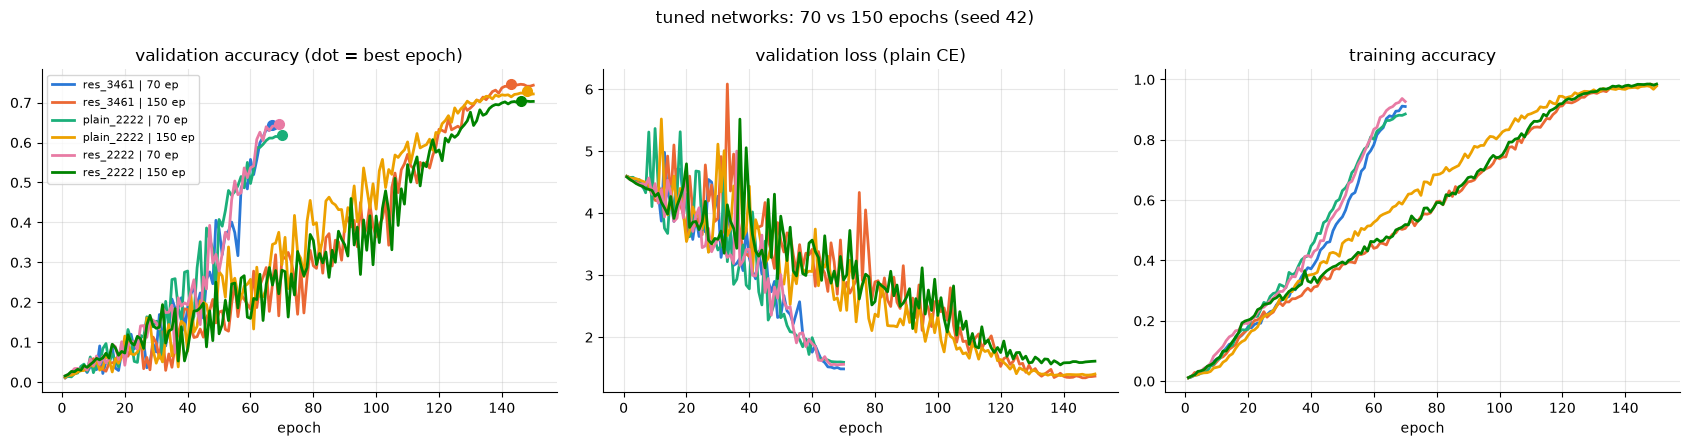

In [28]:
names = finalists(TUNE_N) or []
groups, long_final = {}, {}
for name in names:
    best, runs = best_tuned(name) or (None, [])
    if runs:
        groups[f"{name} | {BASE['epochs']} epochs"] = runs
    long = long_runs(name)
    if long:
        groups[f"{name} | {LONG_EPOCHS} epochs"] = long
    if len(long) == len(SEEDS):
        long_final[name] = long
if groups:
    display(seed_summary(groups))

if names and len(long_final) == len(names):
    ranked = sorted(long_final, key=lambda n: -seed_mean(long_final[n]))
    for n in ranked:
        runs = long_final[n]
        print(
            f"{n:11s} {LONG_EPOCHS} epochs: val {seed_mean(runs):.3f} ± {seed_std(runs):.3f} | "
            f"test {seed_mean(runs, 'test_acc'):.3f} ± {seed_std(runs, 'test_acc'):.3f} | "
            f"train {seed_mean(runs, 'final_train_acc'):.3f}"
        )
    first, second = ranked[0], ranked[1]
    diff = seed_mean(long_final[first]) - seed_mean(long_final[second])
    noise = max(seed_std(long_final[first]), seed_std(long_final[second]))
    if diff > noise:
        final = first
        print(
            f"-> {first}: better by {diff:.3f}, more than one standard deviation ({noise:.3f})"
        )
    else:
        final = min((first, second), key=simplicity)
        print(f"-> a tie ({diff:.3f} <= {noise:.3f}): the simpler network, {final}")
    print("final configuration:", run_overrides(long_final[final][0]))
    curves = {}
    for n in ranked:
        curves[f"{n} | {BASE['epochs']} ep"] = best_tuned(n)[1][0]
        curves[f"{n} | {LONG_EPOCHS} ep"] = long_final[n][0]
    plot_curves(
        curves, f"tuned networks: {BASE['epochs']} vs {LONG_EPOCHS} epochs (seed 42)"
    )

## Ablation of the final model

The ladder and the depth x residual experiment *added* components one at a time to a plain network. To prove that every
design choice of the **final model** contributes to its accuracy, we now do the converse: starting from the final
network with its final configuration (150 epochs), we **remove one component at a time**, retrain, and compare with the
full model. Every ablation uses the same three seeds and changes exactly one thing; learning rate, epochs and all the
other settings stay those of the final model.

| ablation | what changes | component tested |
|---|---|---|
| `no_batchnorm` | BatchNorm removed (convolutions get a bias back) | architecture |
| `no_gap` | flatten + linear head instead of global average pooling | architecture |
| `no_residual` | skip connections removed (plain network) | architecture |
| `no_stage4` | the 512-channel stage removed | architecture |
| `shallow` | one block per stage instead of the final layout | architecture |
| `no_augmentation` | no random resized crop and no horizontal flip | training recipe |
| `no_erasing` | no random erasing | training recipe |
| `no_label_smoothing` | plain cross-entropy | training recipe |
| `no_weight_decay` | weight decay 0 | training recipe |
| `cosine` | cosine schedule with warmup instead of one-cycle | training recipe |
| `no_batchnorm_lr0.01`, `no_gap_lr0.01` | the same removals at a learning rate of 0.01 | control |

**Control.** In the ladder, networks without BatchNorm or with the flatten head were unstable at the high learning
rates that the final model uses. A removal could then look harmful only because the learning rate does not suit it, as
in the learning-rate sweep of the ladder: for these two components we also train the removal at lr 0.01, and report
both.

**Reading the table.** `Δ val` is the validation accuracy of the ablated network minus that of the full model; a
component is useful if removing it lowers the accuracy by more than the seed noise (`beyond noise`: the drop exceeds
the larger standard deviation of the two). The train accuracy tells *how* a component helps: removing a regularizer
raises the train-validation gap, removing capacity or an optimization aid lowers the train accuracy itself.

In [31]:
# The final model (selected above) and its ablations: each one changes exactly one component of its configuration
FINAL_NET = globals().get("final")
ABLATION_GROUP = "ablation"
ABLATION_LR_CONTROL = (
    0.01  # lr of the control runs for the components that make training unstable
)


def make_ablations(base):
    # {name: (kind, overrides)} on top of the configuration `base` of the final model; removals that would not
    # change `base` (e.g. no_residual on a plain network) are left out.
    channels, blocks = tuple(base["channels"]), tuple(base["blocks"])
    candidates = {
        "no_batchnorm": ("architecture", dict(batchnorm=False)),
        "no_gap": ("architecture", dict(gap=False)),
        "no_residual": ("architecture", dict(residual=False)),
        "no_stage4": ("architecture", dict(channels=channels[:3], blocks=blocks[:3])),
        "shallow": ("architecture", dict(blocks=(1,) * len(blocks))),
        "no_augmentation": ("recipe", dict(augment=False)),
        "no_erasing": ("recipe", dict(random_erasing=0.0)),
        "no_label_smoothing": ("recipe", dict(label_smoothing=0.0)),
        "no_weight_decay": ("recipe", dict(weight_decay=0.0)),
        "cosine": ("recipe", dict(schedule="cosine")),
        "no_batchnorm_lr0.01": (
            "control",
            dict(batchnorm=False, lr=ABLATION_LR_CONTROL),
        ),
        "no_gap_lr0.01": ("control", dict(gap=False, lr=ABLATION_LR_CONTROL)),
    }
    same = lambda a, b: json.dumps(a) == json.dumps(b)  # tuples and lists compare equal
    return {
        n: (kind, over)
        for n, (kind, over) in candidates.items()
        if any(not same(base.get(k), v) for k, v in over.items())
    }


if FINAL_NET is None or not long_runs(FINAL_NET):
    ABLATION_BASE, ABLATIONS = None, {}
    print("the final model is not available yet: train the longer runs first")
else:
    ABLATION_BASE = run_overrides(long_runs(FINAL_NET)[0])
    ABLATIONS = make_ablations(ABLATION_BASE)
    print(
        f"final model: {FINAL_NET}, {ABLATION_BASE['epochs']} epochs, lr {ABLATION_BASE['lr']:g}"
    )
    for name, (kind, over) in ABLATIONS.items():
        print(f"{name:22s} {kind:13s} {over}")

final model: res_3461, 150 epochs, lr 0.05
no_batchnorm           architecture  {'batchnorm': False}
no_gap                 architecture  {'gap': False}
no_residual            architecture  {'residual': False}
no_stage4              architecture  {'channels': (64, 128, 256), 'blocks': (3, 4, 6)}
shallow                architecture  {'blocks': (1, 1, 1, 1)}
no_augmentation        recipe        {'augment': False}
no_erasing             recipe        {'random_erasing': 0.0}
no_label_smoothing     recipe        {'label_smoothing': 0.0}
no_weight_decay        recipe        {'weight_decay': 0.0}


In [32]:
# [run]
if TRAIN:
    for name, (kind, over) in ABLATIONS.items():
        for seed in SEEDS:
            run_experiment(
                f"{name}_s{seed}",
                ABLATION_GROUP,
                note=f"ablation: {name}",
                **{**ABLATION_BASE, **over, "seed": seed},
            )

skip ablation/no_batchnorm_s42: best val 0.011 (already trained)
skip ablation/no_batchnorm_s43: best val 0.010 (already trained)
skip ablation/no_batchnorm_s44: best val 0.010 (already trained)
skip ablation/no_gap_s42: best val 0.520 (already trained)
skip ablation/no_gap_s43: best val 0.508 (already trained)
skip ablation/no_gap_s44: best val 0.511 (already trained)
skip ablation/no_residual_s42: best val 0.540 (already trained)
skip ablation/no_residual_s43: best val 0.584 (already trained)
skip ablation/no_residual_s44: best val 0.575 (already trained)
skip ablation/no_stage4_s42: best val 0.731 (already trained)
skip ablation/no_stage4_s43: best val 0.726 (already trained)
skip ablation/no_stage4_s44: best val 0.723 (already trained)
skip ablation/shallow_s42: best val 0.657 (already trained)
skip ablation/shallow_s43: best val 0.658 (already trained)
skip ablation/shallow_s44: best val 0.655 (already trained)
skip ablation/no_augmentation_s42: best val 0.560 (already trained)
sk

### Results of the ablation

Mean ± standard deviation over three seeds, each ablated network against the full model (the longer training of the
final network, same seeds). Runs that diverged before the first validation have no checkpoint and are left out of the
means (`diverged` counts them).

In [33]:
def ablation_table():
    # One row per configuration: full model first, then the ablations; None until at least one run exists.
    runs = load_group(ABLATION_GROUP)
    groups = {"full model": ("", {}, long_runs(FINAL_NET))}
    for name, (kind, over) in ABLATIONS.items():
        got = [runs[f"{name}_s{s}"] for s in SEEDS if f"{name}_s{s}" in runs]
        if got:
            groups[name] = (kind, over, got)
    if len(groups) == 1:
        return None

    def stats(rs, key):
        v = np.array([r[key] for r in rs if r["best_epoch"] > 0], dtype=float)
        return (
            (v.mean(), v.std(ddof=1) if len(v) > 1 else np.nan)
            if len(v)
            else (np.nan, np.nan)
        )

    ref_val, ref_test = (
        stats(groups["full model"][2], "best_val_acc"),
        stats(groups["full model"][2], "test_acc"),
    )
    rows = []
    for name, (kind, over, rs) in groups.items():
        val, test = stats(rs, "best_val_acc"), stats(rs, "test_acc")
        train, gap = (
            stats(rs, "final_train_acc")[0],
            np.nanmean([r["final_train_acc"] - r["final_val_acc"] for r in rs]),
        )
        noise = np.nanmax([val[1], ref_val[1]])
        rows.append(
            dict(
                run=name,
                kind=kind,
                change=", ".join(f"{k}={v}" for k, v in over.items()),
                lr=rs[0]["config"]["lr"],
                params_M=rs[0]["params"] / 1e6,
                seeds=len(rs),
                diverged=f"{sum(r['diverged'] for r in rs)}/{len(rs)}",
                val_mean=val[0],
                val_std=val[1],
                d_val=val[0] - ref_val[0],
                test_mean=test[0],
                test_std=test[1],
                d_test=test[0] - ref_test[0],
                train=train,
                gap=gap,
                beyond_noise=(
                    ""
                    if name == "full model"
                    else "yes"
                    if ref_val[0] - val[0] > noise
                    else "no"
                ),
            )
        )
    return pd.DataFrame(rows).set_index("run")


def style_ablation(table):
    return (
        table.rename(
            columns={
                "d_val": "Δ val",
                "d_test": "Δ test",
                "val_mean": "val",
                "val_std": "± val",
                "test_mean": "test",
                "test_std": "± test",
                "train": "train acc",
                "gap": "train-val gap",
                "params_M": "params (M)",
                "beyond_noise": "beyond noise",
            }
        )
        .style.format(
            {
                "lr": "{:g}",
                "params (M)": "{:.2f}",
                "val": "{:.3f}",
                "± val": "{:.3f}",
                "Δ val": "{:+.3f}",
                "test": "{:.3f}",
                "± test": "{:.3f}",
                "Δ test": "{:+.3f}",
                "train acc": "{:.3f}",
                "train-val gap": "{:+.3f}",
            },
            na_rep="-",
        )
        .background_gradient(
            subset=["Δ val", "Δ test"], cmap="RdYlGn", vmin=-0.4, vmax=0.4
        )
        .set_properties(
            subset=pd.IndexSlice["full model", :], **{"font-weight": "bold"}
        )
    )


ablation = ablation_table() if FINAL_NET is not None and long_runs(FINAL_NET) else None
if ablation is None:
    print("no ablation run yet: run the cell above")
else:
    display(style_ablation(ablation))

,kind,change,lr,params (M),seeds,diverged,val,± val,Δ val,test,± test,Δ test,train acc,train-val gap,beyond noise
run,,,,,,,,,,,,,,,
full model,,,0.05,11.91,3,0/3,0.740,0.007,+0.000,0.742,0.002,+0.000,0.982,+0.244,
no_batchnorm,architecture,batchnorm=False,0.05,11.91,3,0/3,0.010,0.000,-0.730,0.010,0.000,-0.732,0.010,+0.000,yes
no_gap,architecture,gap=False,0.05,14.37,3,0/3,0.513,0.006,-0.227,0.518,0.005,-0.224,0.990,+0.481,yes
no_residual,architecture,residual=False,0.05,11.74,3,0/3,0.566,0.023,-0.174,0.571,0.016,-0.171,0.690,+0.126,yes
no_stage4,architecture,"channels=(64, 128, 256), blocks=(3, 4, 6)",0.05,8.22,3,0/3,0.727,0.004,-0.014,0.726,0.004,-0.016,0.979,+0.255,yes
shallow,architecture,"blocks=(1, 1, 1, 1)",0.05,4.98,3,0/3,0.657,0.002,-0.084,0.655,0.004,-0.087,0.989,+0.334,yes
no_augmentation,recipe,augment=False,0.05,11.91,3,0/3,0.562,0.006,-0.179,0.571,0.005,-0.172,0.999,+0.442,yes
no_erasing,recipe,random_erasing=0.0,0.05,11.91,3,0/3,0.744,0.004,+0.003,0.738,0.004,-0.004,1.000,+0.260,no
no_label_smoothing,recipe,label_smoothing=0.0,0.05,11.91,3,0/3,0.722,0.004,-0.018,0.727,0.008,-0.015,0.979,+0.259,yes


The two plots below show the same table. **Left**: the change in validation (dark bars) and test (light bars) accuracy
caused by each removal, with the standard deviation over seeds (the grey band is the seed noise of the full model); components are ordered by how much their removal costs.
**Right**: where each network ends up in the training accuracy / validation accuracy plane. A network far below the
dashed diagonal overfits. Removing capacity or an optimization aid moves a network to the left (it fits its training
set worse); removing a regularizer moves it to the right and down (it fits better and generalizes worse).

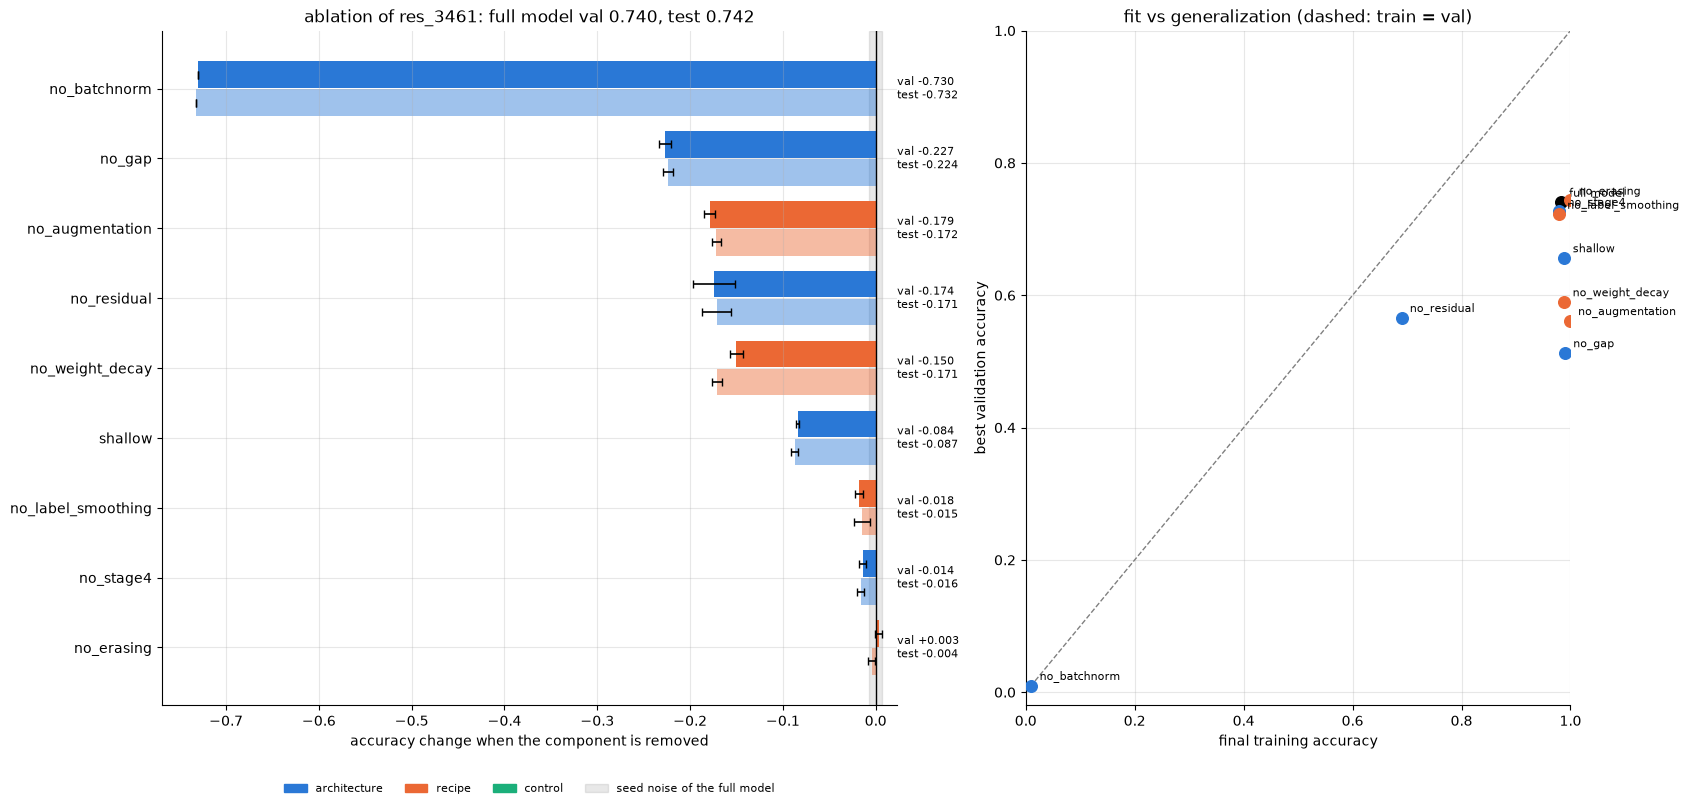

In [34]:
if ablation is not None:
    full = ablation.loc["full model"]
    abl = ablation.drop(index="full model").sort_values(
        "d_val", ascending=True
    )  # the most costly removal on top
    kind_color = {"architecture": COLORS[0], "recipe": COLORS[1], "control": COLORS[2]}
    ys = np.arange(len(abl))

    fig, (ax, ax2) = plt.subplots(
        1,
        2,
        figsize=(17, 0.55 * len(abl) + 3.2),
        gridspec_kw=dict(width_ratios=[1.35, 1]),
    )
    ax.axvspan(-full.val_std, full.val_std, color="gray", alpha=0.18)
    ax.barh(
        ys - 0.2,
        abl.d_val,
        0.38,
        xerr=abl.val_std.fillna(0),
        color=[kind_color[k] for k in abl.kind],
        error_kw=dict(lw=1.2, capsize=3),
    )
    ax.barh(
        ys + 0.2,
        abl.d_test,
        0.38,
        xerr=abl.test_std.fillna(0),
        color=[kind_color[k] for k in abl.kind],
        alpha=0.45,
        error_kw=dict(lw=1.2, capsize=3),
    )
    right = max(0.02, np.nanmax(abl.d_val) + 0.02)
    for y, d, t in zip(ys, abl.d_val, abl.d_test):
        ax.text(
            right, y, f"val {d:+.3f}\ntest {t:+.3f}", va="center", ha="left", fontsize=8
        )
    ax.set_xlim(None, right)
    ax.set_yticks(ys, abl.index)
    ax.invert_yaxis()
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel("accuracy change when the component is removed")
    ax.set_title(
        f"ablation of {FINAL_NET}: full model val {full.val_mean:.3f}, test {full.test_mean:.3f}"
    )
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in kind_color.values()]
    band = plt.Rectangle((0, 0), 1, 1, color="gray", alpha=0.18)
    ax.legend(
        handles + [band],
        list(kind_color) + ["seed noise of the full model"],
        loc="upper center",
        bbox_to_anchor=(0.5, -0.1),
        ncol=4,
        fontsize=8,
        frameon=False,
    )

    lim = [np.nanmin(ablation.val_mean) - 0.03, 1.0]
    ax2.plot([0, 1], [0, 1], "--", color="gray", lw=1)
    for name, row in ablation.iterrows():
        c = "black" if name == "full model" else kind_color[row.kind]
        ax2.scatter(row.train, row.val_mean, color=c, s=70, zorder=3)
        ax2.annotate(
            name,
            (row.train, row.val_mean),
            textcoords="offset points",
            xytext=(6, 4),
            fontsize=8,
        )
    ax2.set_xlim(max(np.nanmin(ablation.train) - 0.05, 0), 1.0)
    ax2.set_ylim(*lim)
    ax2.set_xlabel("final training accuracy")
    ax2.set_ylabel("best validation accuracy")
    ax2.set_title("fit vs generalization (dashed: train = val)")
    plt.tight_layout()
    plt.show()

Training curves of every ablation (seed 42) against the full model: validation accuracy (solid) and training accuracy
(dashed).

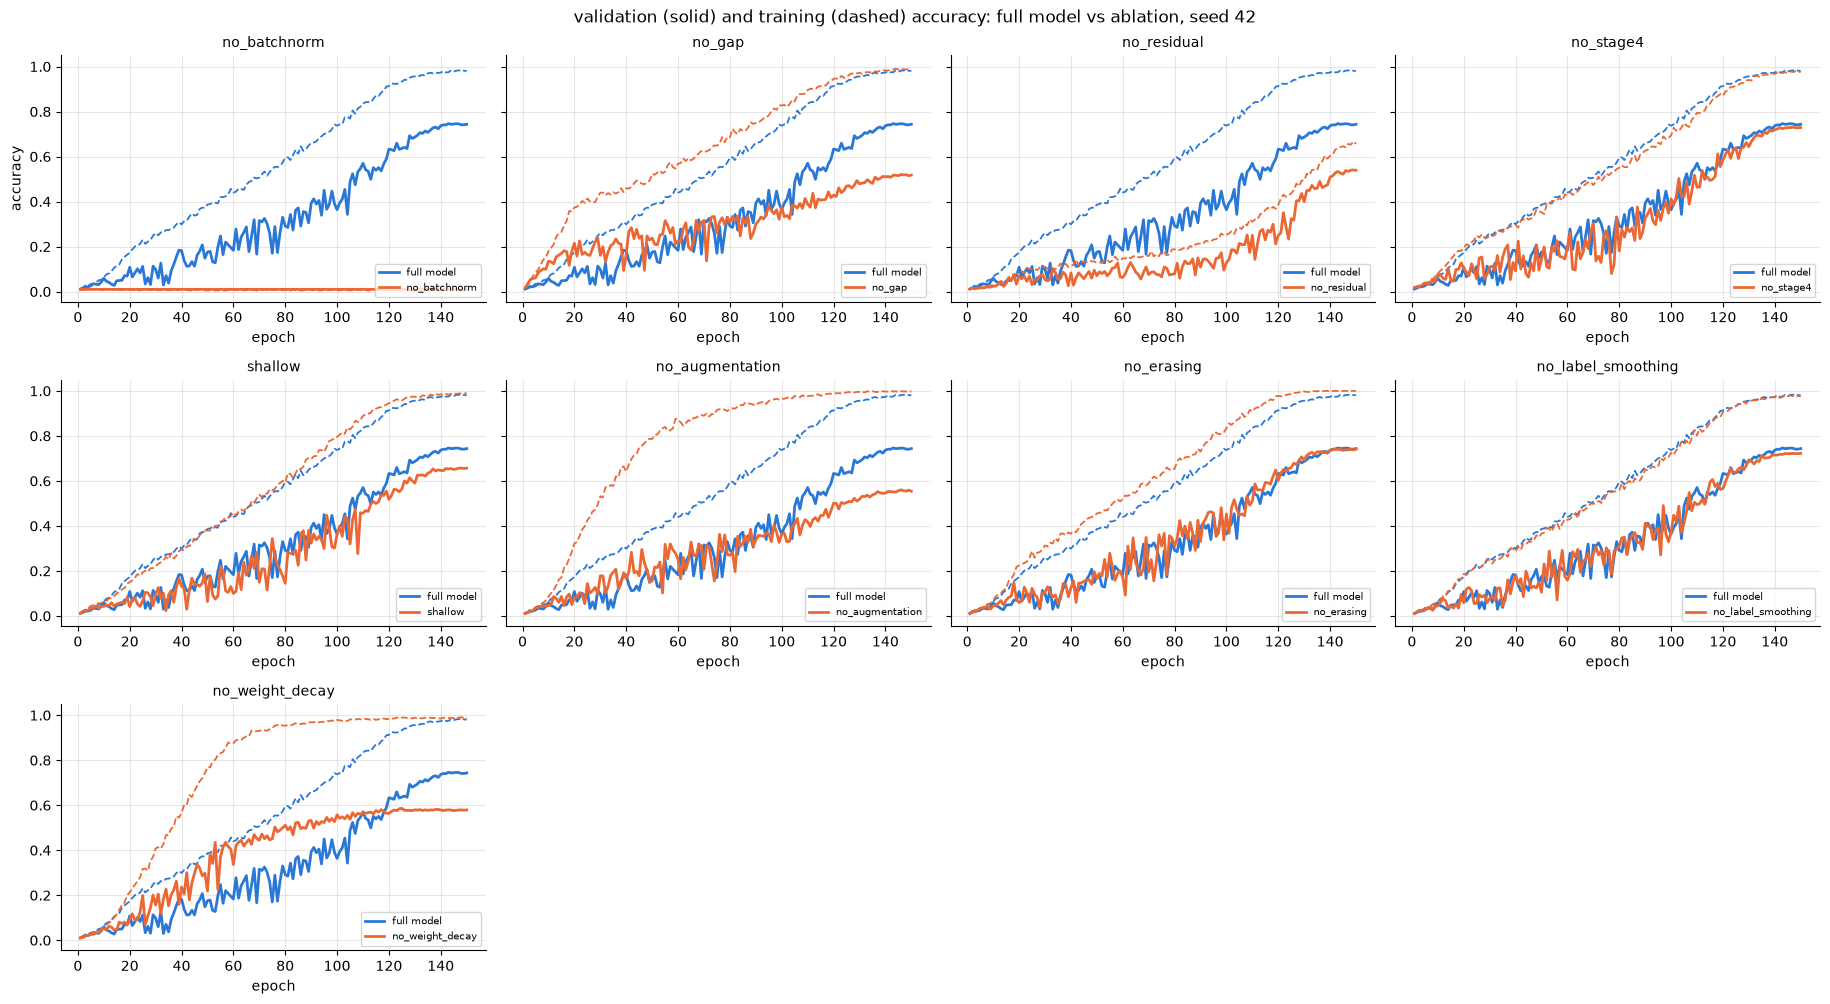

In [35]:
if ablation is not None:
    runs = load_group(ABLATION_GROUP)
    names = [n for n in ablation.index if n != "full model"]
    reference = long_runs(FINAL_NET)[0]
    cols = 4
    rows_ = int(np.ceil(len(names) / cols))
    fig, axes = plt.subplots(
        rows_, cols, figsize=(4.6 * cols, 3.4 * rows_), sharey=True, squeeze=False
    )
    for ax, name in zip(axes.ravel(), names):
        r = runs[f"{name}_s{SEEDS[0]}"] if f"{name}_s{SEEDS[0]}" in runs else None
        for label, run, color in (
            ("full model", reference, COLORS[0]),
            (name, r, COLORS[1]),
        ):
            if run is None or not run["history"]["val_acc"]:
                continue
            h = run["history"]
            ep = range(1, len(h["val_acc"]) + 1)
            ax.plot(ep, h["val_acc"], color=color, label=label)
            ax.plot(ep, h["train_acc"], color=color, ls="--", lw=1.3)
        ax.set_title(name, fontsize=10)
        ax.set_xlabel("epoch")
        ax.legend(fontsize=7, loc="lower right")
    for ax in axes.ravel()[len(names) :]:
        ax.axis("off")
    axes[0, 0].set_ylabel("accuracy")
    fig.suptitle(
        "validation (solid) and training (dashed) accuracy: full model vs ablation, seed 42"
    )
    plt.tight_layout()
    plt.show()

# Part 2: fine-tune a pretrained ResNet-18

We now fine-tune the ResNet-18 of PyTorch (`torchvision.models.resnet18`), pretrained on ImageNet-1K (V1), on the same
data, split and evaluation protocol of Part 1. Everything defined above is reused as is: data pipeline and
augmentation, training loop (`fit`), experiment runner (`run_experiment`), storage of the results and plots. The
**only two differences** with respect to Part 1 are handled by the configuration key `pretrained=True`:

1. the network: `build_model` returns the pretrained ResNet-18 with a new 100-way classifier
   (`Dropout -> Linear(512, 100)`, initialized at random) instead of `AircraftNet`;
2. the input normalization: the pretrained weights expect the mean and standard deviation of ImageNet
   (`get_data(..., imagenet_stats=True)`), not those of our training split.

Results are stored in `results/part2A`.

## 2A: the hyperparameters of Part 1

As the assignment requires, we fine-tune the whole ResNet-18 with the **training hyperparameters of the best model of
Part 1** (`res_3461`, with its tuned recipe, trained for the final 150 epochs), and nothing else is tuned:

| hyperparameter | value |
|---|---|
| resolution, batch size | 224 x 224, 64 |
| epochs | 150 (`LONG_EPOCHS`) |
| optimizer | SGD, momentum 0.9 |
| learning rate, schedule | 0.05, one-cycle (rise over the first 30% of the epochs, then cosine decay) |
| weight decay | 5e-3 (convolution and linear weights only) |
| label smoothing, dropout | 0.2, 0 |
| augmentation | random resized crop (50-100% of the area) + horizontal flip, random erasing (p = 0.25) |
| seeds | 42, 43, 44 |

All layers are fine-tuned with this single learning rate. The learning rate of 0.05 was tuned for a network trained
from scratch; this experiment shows how it behaves on pretrained weights, which is the starting point of 2B.

In [36]:
# the training hyperparameters of the best model of Part 1 (res_3461, configuration cfg05), applied to the pretrained net
FINETUNE = dict(
    pretrained=True,
    augment=True,
    crop_scale=(0.5, 1.0),
    dropout=0.0,
    epochs=LONG_EPOCHS,
    lr=0.05,
    weight_decay=5e-3,
    label_smoothing=0.2,
    random_erasing=0.25,
    schedule="onecycle",
)

# sanity check: same recipe as the stored best configuration of res_3461 in Part 1, when it is available
best = best_tuned("res_3461")
if best is not None:
    stored = run_overrides(best[1][0])
    differences = {
        k: (stored.get(k), v)
        for k, v in FINETUNE.items()
        if k not in ("pretrained", "epochs")
        and json.loads(json.dumps(stored.get(k))) != json.loads(json.dumps(v))
    }
    print(
        "same recipe as Part 1"
        if not differences
        else f"WARNING: differs from Part 1 (part 1, here): {differences}"
    )

same recipe as Part 1


Layer (type (var_name))                  Output Shape              Param #
ResNet (ResNet)                          [1, 100]                  --
├─Conv2d (conv1)                         [1, 64, 112, 112]         9,408
├─BatchNorm2d (bn1)                      [1, 64, 112, 112]         128
├─ReLU (relu)                            [1, 64, 112, 112]         --
├─MaxPool2d (maxpool)                    [1, 64, 56, 56]           --
├─Sequential (layer1)                    [1, 64, 56, 56]           --
│    └─BasicBlock (0)                    [1, 64, 56, 56]           --
│    │    └─Conv2d (conv1)               [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d (bn1)            [1, 64, 56, 56]           128
│    │    └─ReLU (relu)                  [1, 64, 56, 56]           --
│    │    └─Conv2d (conv2)               [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d (bn2)            [1, 64, 56, 56]           128
│    │    └─ReLU (relu)                  [1, 64, 56, 56]           --
│

### Fine-tuning

Three seeds, same configuration: there is no learning-rate sweep, so the mean over the seeds is not biased by a
selection (in Part 1 the seed-42 run of a configuration is the best of three learning rates).

In [37]:
# [run]
if TRAIN:
    for seed in SEEDS:
        run_experiment(
            f"resnet18_ft_s{seed}",
            "finetune",
            note="hyperparameters of part 1",
            results_dir=RESULTS_DIR_2A,
            seed=seed,
            **FINETUNE,
        )

skip finetune/resnet18_ft_s42: best val 0.719 (already trained)
skip finetune/resnet18_ft_s43: best val 0.726 (already trained)
skip finetune/resnet18_ft_s44: best val 0.712 (already trained)


### Results of 2A

Mean ± standard deviation over three seeds, compared with the best model of Part 1 trained from scratch with the same
hyperparameters (`res_3461`, 150 epochs). The curves are the seed-42 runs.

,lr,seeds,params_M,val_mean,val_std,test_mean,test_std,train_mean
run,,,,,,,,
"resnet18_ft (pretrained, 2A)",0.05,3,11.23,0.719,0.007,0.724,0.007,0.993
"res_3461 (from scratch, part 1)",0.05,3,11.91,0.740,0.007,0.742,0.002,0.982


resnet18_ft (pretrained, 2A)     val 0.719 ± 0.007 | test 0.724 ± 0.007 | train 0.993
res_3461 (from scratch, part 1)  val 0.740 ± 0.007 | test 0.742 ± 0.002 | train 0.982


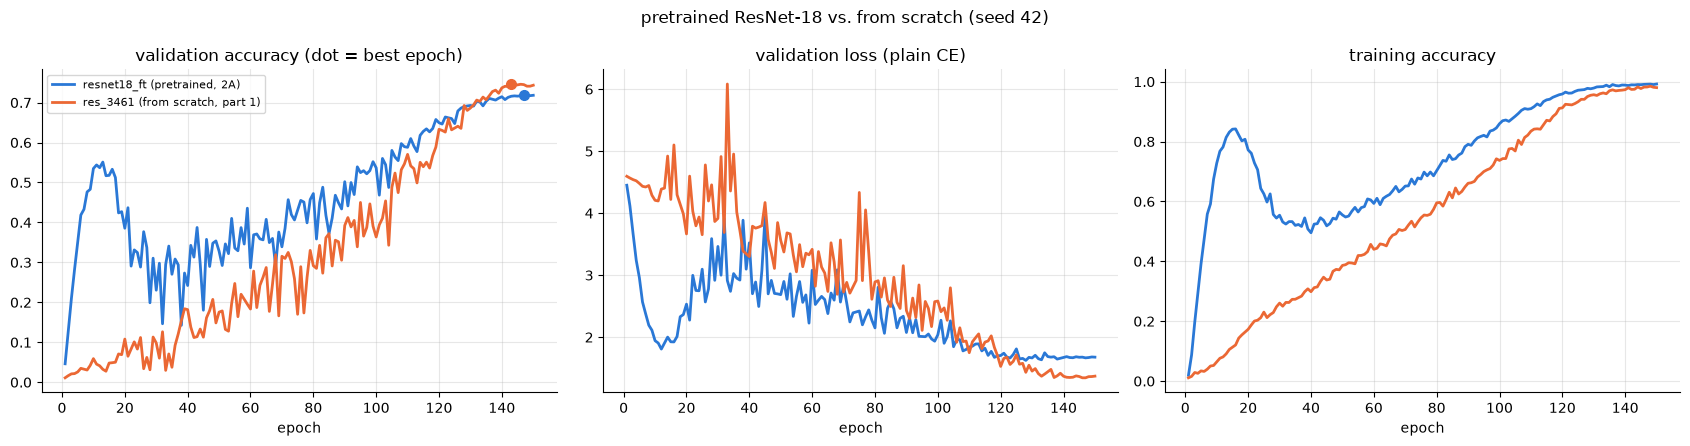

In [38]:
finetune = load_group("finetune", RESULTS_DIR_2A)
groups = {
    "resnet18_ft (pretrained, 2A)": list(finetune.values()),
    "res_3461 (from scratch, part 1)": long_runs("res_3461"),
}
groups = {k: v for k, v in groups.items() if v}
if groups:
    display(seed_summary(groups))
    for label, runs in groups.items():
        print(
            f"{label:32s} val {seed_mean(runs):.3f} ± {seed_std(runs):.3f} | "
            f"test {seed_mean(runs, 'test_acc'):.3f} ± {seed_std(runs, 'test_acc'):.3f} | "
            f"train {seed_mean(runs, 'final_train_acc'):.3f}"
        )
    plot_curves(
        {label: runs[0] for label, runs in groups.items()},
        "pretrained ResNet-18 vs. from scratch (seed 42)",
    )
else:
    print("no stored run yet")

## 2B: tuned fine-tuning

*To be added.*